# Localización temporal de la Magnetic Pileup Boundary de Marte con MAVEN MAG y SWEA

**Trabajo final: Machine Learning en Geofluidos — Modelo CNN multimodal con ranking.**  


## 1. Contexto físico

Marte no presenta un dipolo magnético global dominante como el terrestre, aunque posee campos remanentes de origen cortical. El viento solar transporta el campo magnético interplanetario; al interactuar con el planeta, se forma una región de plasma desacelerado detrás del **bow shock (BS)**, denominada **magnetovaina**. Más cerca del planeta aparece la región de acumulación magnética (*magnetic pileup region*, MPR), perteneciente a la magnetosfera inducida. La **MPB** separa aproximadamente magnetovaina y MPR: sus firmas pueden incluir cambios de intensidad y fluctuaciones del campo magnético y cambios espectrales en los electrones supratérmicos.

La misión **MAVEN** proporciona observaciones complementarias: **MAG** mide \(B_x,B_y,B_z\) y **SWEA** mide distribuciones de electrones, que en este trabajo se reducen a una serie espectral promedio por tiempo. Combinarlas permite estudiar una transición entre regímenes de plasma, no solo una discontinuidad en \(|\mathbf B|\).

Representamos la **MPB y el bow shock** mediante las cónicas axisimétricas ajustadas por Vignes et al. (2000):

\[
r=\frac{L}{1+\varepsilon\cos\theta},\qquad
X'=X_0+r\cos\theta,\qquad \rho=r\sin\theta.
\]

Aquí \(\rho=\sqrt{Y'^2+Z'^2}\); los ángulos se miden desde un foco en \((X_0,0,0)\) y se utiliza el sistema **MSO aberrado 4°** del modelo. Las distancias están en radios marcianos \(R_M\).

| Frontera | \(X_0/R_M\) | \(\varepsilon\) | \(L/R_M\) |
| --- | ---: | ---: | ---: |
| MPB | 0.78 | 0.90 | 0.96 |
| Bow shock | 0.64 | 1.03 | 2.04 |

Los parámetros se toman del [código de cálculo de cruces de Vignes utilizado en este proyecto](https://github.com/CamilaMastronardi/MAVEN-Vignes-Crossings/blob/main/src/ComputeVignesCrossings.py), basado en **Vignes et al. (2000), Geophysical Research Letters, 27, 49–52**. Se trata de superficies **medias empíricas**, no de fronteras instantáneas ni de una trayectoria observada por MAVEN.


In [1]:
# 1.1 Entorno portátil: se ejecuta desde una carpeta cualquiera (local o Colab).
import os, sys, subprocess, importlib.util, json, hashlib, warnings
from pathlib import Path

REPO_URL = 'https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning.git'
# Commit con la separación src/preprocessing / src/model y los 3 barridos V7b.
SOURCE_COMMIT = '06f428d79ca9e2b3c6abf48336c9c29d70cfee4e'
OVERRIDE_ROOT = os.environ.get('MAVEN_V7B_REPO_DIR', '').strip()
START_DIRECTORY = Path.cwd().resolve()

if OVERRIDE_ROOT:
    PROJECT_ROOT = Path(OVERRIDE_ROOT).expanduser().resolve()
    if not (PROJECT_ROOT / 'src/model/v7b.py').is_file():
        raise FileNotFoundError('MAVEN_V7B_REPO_DIR debe apuntar al árbol V7b reorganizado.')
else:
    candidates = [START_DIRECTORY, START_DIRECTORY.parent]
    available = [p for p in candidates if (p / 'src/model/v7b.py').is_file()]
    if available:
        PROJECT_ROOT = available[0]
    else:
        PROJECT_ROOT = START_DIRECTORY / '_maven_v7b_source'
        if not (PROJECT_ROOT / '.git').is_dir():
            subprocess.run(['git','clone','--quiet','--branch','main',
                            '--single-branch',REPO_URL,str(PROJECT_ROOT)],check=True)
        subprocess.run(['git','-C',str(PROJECT_ROOT),'fetch','--quiet','origin',
                        'main'],check=True)
        subprocess.run(['git','-C',str(PROJECT_ROOT),'checkout','--quiet','--detach',SOURCE_COMMIT],check=True)

# Instala solamente dependencias faltantes, sin tocar las bibliotecas instaladas.
deps = {'numpy':'numpy', 'pandas':'pandas', 'matplotlib':'matplotlib',
        'scipy':'scipy', 'sklearn':'scikit-learn', 'torch':'torch',
        'google.cloud.bigquery':'google-cloud-bigquery'}
def module_available(name):
    try:
        return importlib.util.find_spec(name) is not None
    except ModuleNotFoundError:
        return False
missing = [package for module,package in deps.items() if not module_available(module)]
if missing:
    subprocess.run([sys.executable,'-m','pip','install','--quiet',*missing],check=True)

# Fuente y datos pueden vivir en carpetas distintas. Esto permite reutilizar
# las cachés y checkpoints del repositorio local antiguo sin duplicar BigQuery.
data_root_override = os.environ.get('MAVEN_V7B_DATA_ROOT','').strip()
if data_root_override:
    DATA_ROOT = Path(data_root_override).expanduser().resolve()
else:
    data_candidates=[START_DIRECTORY,START_DIRECTORY.parent,PROJECT_ROOT]
    DATA_ROOT = next((d for d in data_candidates
                      if (d/'data/splits/cv4_monthly_manifest.csv').is_file()),PROJECT_ROOT)
if not (DATA_ROOT/'data/splits/cv4_monthly_manifest.csv').is_file():
    raise FileNotFoundError('No se encontró el manifiesto CV en DATA_ROOT.')

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)
print('Código V7b:', PROJECT_ROOT)
print('Datos y resultados locales:', DATA_ROOT)
print('Referencia:', SOURCE_COMMIT if not OVERRIDE_ROOT else 'carpeta local indicada por la usuaria')


Código V7b: /home/cami/Codigos/MAVEN-MPB-DeepLearning
Datos y resultados locales: /home/cami/Codigos/MAVEN-MPB-DeepLearning
Referencia: 06f428d79ca9e2b3c6abf48336c9c29d70cfee4e


In [2]:
# 1.2 Configuración central.
from dataclasses import dataclass
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from IPython.display import display

@dataclass(frozen=True)
class Config:
    rank_weight: float = 2.0
    rank_margin: float = 0.25
    region_weight: float = 0.5  # Provisional mientras se analiza el tercer barrido.
    reconstruction_weight: float = 0.15
    learning_rate: float = 3e-4
    batch_size: int = 16
    seed: int = 42
    max_epochs: int = 100
    min_epochs: int = 10
    patience: int = 8
    rank_control_step_s: int = 120
    rank_positives_per_event: int = 2
    rank_hard_negatives: int = 2
    rank_random_negatives: int = 2
    evaluation_stride_s: int = 32
    n_folds: int = 4

CFG = Config()
RUN_TRAINING = False  # Poner True SOLO para entrenar/consultar BigQuery.
PILOT_EVENTS_PER_FOLD = 0  # 0 = catálogo completo; 8 = piloto por fold.
FOLD_TO_VISUALIZE = 1
MAX_LATENT_EVENTS = 24
TORCH_THREADS = 2

OUT_DIR = Path(os.environ.get('MAVEN_V7B_NOTEBOOK_RESULTS',
                              str(DATA_ROOT/'results/metrics/v7b_notebook_rank2_margin0p25_region0p5')))
FIG_DIR = Path(os.environ.get('MAVEN_V7B_NOTEBOOK_FIGURES',
                              str(DATA_ROOT/'results/figures/v7b_notebook')))
FIG_DIR.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(TORCH_THREADS)
np.random.seed(CFG.seed)
torch.manual_seed(CFG.seed)
print('Parámetros del experimento:', CFG)
print('Salida de entrenamiento:', OUT_DIR)


Parámetros del experimento: Config(rank_weight=2.0, rank_margin=0.25, region_weight=0.5, reconstruction_weight=0.15, learning_rate=0.0003, batch_size=16, seed=42, max_epochs=100, min_epochs=10, patience=8, rank_control_step_s=120, rank_positives_per_event=2, rank_hard_negatives=2, rank_random_negatives=2, evaluation_stride_s=32, n_folds=4)
Salida de entrenamiento: /home/cami/Codigos/MAVEN-MPB-DeepLearning/results/metrics/v7b_notebook_rank2_margin0p25_region0p5


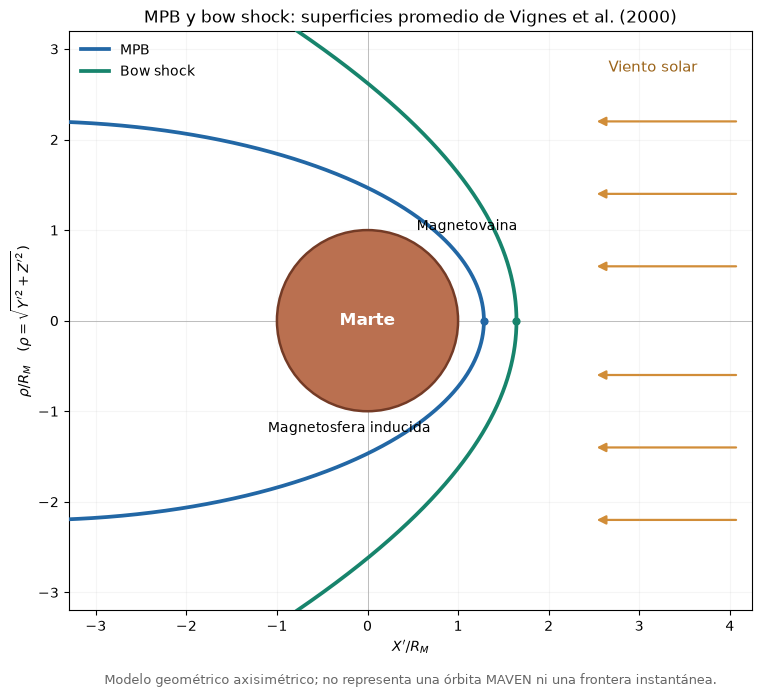

In [3]:
# Figura 1: fronteras promedio de Vignes et al. (2000), no parábolas arbitrarias.
# Plano meridional X'–rho del sistema MSO aberrado (~4°), coordenadas en R_M.
# La revolución alrededor del eje X' genera las superficies axisimétricas 3D.
from matplotlib.patches import Circle, FancyArrowPatch

R_M = 1.0   # Unidad de longitud: radios de Marte
VIGNES_BOUNDARIES = {
    'MPB': {'x0': 0.78, 'epsilon': 0.90, 'L': 0.96, 'color': '#2267a5'},
    'Bow shock': {'x0': 0.64, 'epsilon': 1.03, 'L': 2.04, 'color': '#17846c'},
}

def vignes_meridional(x0, epsilon, L, theta):
    """Genera X' y rho a partir de r=L/(1+eps*cos(theta))."""
    den = 1.0 + epsilon * np.cos(theta)
    r = np.full_like(theta, np.nan, dtype=float)
    np.divide(L, den, out=r, where=den > 1e-9)
    return x0 + r*np.cos(theta), r*np.sin(theta)

# Control geométrico de las posiciones subsolares (theta=0).
for name, p in VIGNES_BOUNDARIES.items():
    nose = p['x0'] + p['L']/(1.0+p['epsilon'])
    assert nose > 1.0, f'{name}: la nariz debe estar fuera de Marte'
assert (VIGNES_BOUNDARIES['Bow shock']['x0'] +
        VIGNES_BOUNDARIES['Bow shock']['L']/
        (1+VIGNES_BOUNDARIES['Bow shock']['epsilon'])) > (
        VIGNES_BOUNDARIES['MPB']['x0'] +
        VIGNES_BOUNDARIES['MPB']['L']/
        (1+VIGNES_BOUNDARIES['MPB']['epsilon']))

fig, ax = plt.subplots(figsize=(11, 7))
theta = np.linspace(0, np.pi, 2200)
xlim, ylim = (-3.3, 4.25), (-3.2, 3.2)

for name, p in VIGNES_BOUNDARIES.items():
    x, rho = vignes_meridional(p['x0'],p['epsilon'],p['L'],theta)
    visible = (np.isfinite(x) & np.isfinite(rho) &
               (x >= xlim[0]) & (x <= xlim[1]) &
               (rho >= 0) & (rho <= ylim[1]))
    x_plot = np.where(visible, x, np.nan)
    rho_plot = np.where(visible, rho, np.nan)
    ax.plot(x_plot, rho_plot, color=p['color'], lw=2.7, label=name, zorder=3)
    ax.plot(x_plot, -rho_plot, color=p['color'], lw=2.7, zorder=3)
    nose = p['x0'] + p['L']/(1+p['epsilon'])
    ax.scatter([nose],[0],s=24,color=p['color'],zorder=4)

# Marte (se dibuja sobre las curvas para ocultar cualquier sección interna).
ax.add_patch(Circle((0,0), R_M, facecolor='#ba7050',
                    edgecolor='#743b26',linewidth=1.8,zorder=5))
ax.text(0,0,'Marte',color='white',weight='bold',
        ha='center',va='center',fontsize=12,zorder=6)

# Dirección de flujo en el sistema aberrado: del Sol hacia Marte (-X').
for y in (-2.2,-1.4,-0.6,0.6,1.4,2.2):
    ax.add_patch(FancyArrowPatch((4.1,y),(2.5,y),
                  arrowstyle='-|>',mutation_scale=13,
                  color='#d18d38',linewidth=1.6,zorder=1))
ax.text(3.15,2.75,'Viento solar',ha='center',fontsize=11,color='#9b641a')
ax.text(1.1,1.0,'Magnetovaina',ha='center',fontsize=10)
ax.text(-0.2,-1.23,'Magnetosfera inducida',ha='center',fontsize=10)

ax.set(xlim=xlim,ylim=ylim,
       xlabel=r"$X'/R_M$",
       ylabel=r"$\rho/R_M\quad (\rho=\sqrt{Y'^2+Z'^2})$",
       title='MPB y bow shock: superficies promedio de Vignes et al. (2000)')
ax.set_aspect('equal',adjustable='box')
ax.axhline(0,color='0.75',linewidth=.7,zorder=0)
ax.axvline(0,color='0.75',linewidth=.7,zorder=0)
ax.grid(alpha=.12)
ax.legend(loc='upper left',frameon=False)
fig.text(0.5,0.015,'Modelo geométrico axisimétrico; no representa una órbita MAVEN ni una frontera instantánea.',
         ha='center',fontsize=9,color='0.4')
fig.tight_layout(rect=(0,0.035,1,1))
fig.savefig(FIG_DIR/'01_esquema_fisico_vignes.png',dpi=180,bbox_inches='tight')
plt.show()


## 2. Catálogo, instrumentos y particiones

El catálogo contiene **569 cruces MPB**; el manifiesto registra cobertura temporal MAG para 569 y SWEA para 559. La cantidad efectiva de ventanas conjuntas válidas depende de los datos medidos y sus gaps: **no** inferimos señales SWEA donde faltan observaciones.

| Instrumento | Entrada de V7b | Cadencia aproximada | Transformación |
|---|---|---|---|
| MAG | \(B_x,B_y,B_z,|\mathbf B|\) (4) | 1 s | normalización por canal, solo FIT |
| SWEA | 12 energías logarítmicas entre 30–300 eV | ~32 s | promedio angular, interpolación **en energía**, `log1p`, normalización solo FIT |

Cada candidato tiene un soporte temporal de **600 s**, independientemente de su cadencia nativa. Se rechazan ventanas incompletas, con gaps incompatibles o valores inválidos. No se interpola SWEA en el tiempo.

Para evaluar el modelo se utiliza una **validación cruzada de cuatro folds**, agrupando los eventos por mes UTC para evitar mezclar observaciones temporalmente cercanas. En cada entrenamiento, tres folds se destinan al entrenamiento y el restante a la evaluación. Dentro del conjunto de entrenamiento se reserva una pequeña fracción de meses (**MONITOR**) para controlar la evolución de la red y seleccionar la mejor época, mientras que el resto (**FIT**) se utiliza para actualizar sus parámetros. Se evita que los distintos conjuntos compartan mediciones temporales y la normalización se calcula exclusivamente a partir de FIT.


Cruces anotados: 569 | MAG en manifiesto: 569 | SWEA en manifiesto: 559


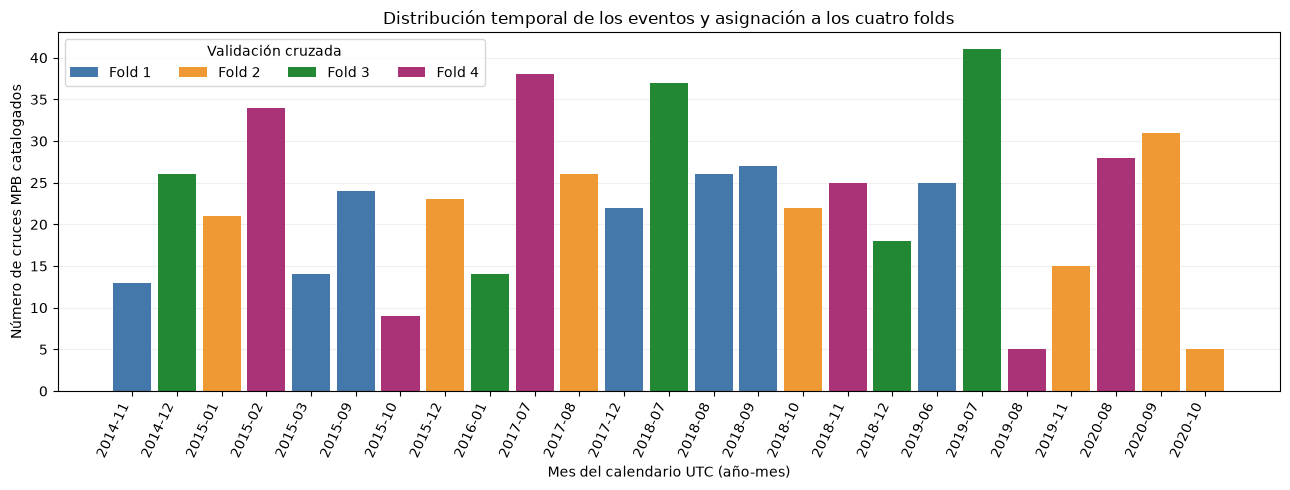

Fold 1: FIT 350, MONITOR 63, VAL 146, FIT excluidos por solapamiento 0
Fold 2: FIT 357, MONITOR 63, VAL 139, FIT excluidos por solapamiento 0
Fold 3: FIT 394, MONITOR 30, VAL 135, FIT excluidos por solapamiento 0
Fold 4: FIT 379, MONITOR 41, VAL 139, FIT excluidos por solapamiento 0


In [4]:
# 2.1 Estadísticas del catálogo y asignación mensual; no usa BigQuery.
from src.preprocessing.catalog import read_manifest
from src.preprocessing.cv_splits import split_inner_monitor_months, check_disjoint_supports
from src.preprocessing.swea_cache import ENERGY_EV, SweaEventCache
from src.preprocessing.mag_cache import MagEventCache
from src.preprocessing.native_windows import extract_clip, collate_dual
from src.preprocessing import bigquery_source as bq

MANIFEST = DATA_ROOT/'data/splits/cv4_monthly_manifest.csv'
rows = read_manifest(MANIFEST)
for r in rows:
    r['bs_time'] = bq.to_utc(r['bs_timestamp_utc'])
print('Cruces anotados:', len(rows),
      '| MAG en manifiesto:',sum(r['mag_available']=='1' for r in rows),
      '| SWEA en manifiesto:',sum(r['swea_available']=='1' for r in rows))

# Un bloque corresponde a un mes calendario UTC (año-mes), sin distinguir
# grupos de catálogo. El color identifica el fold al que pertenece cada mes.
monthly = pd.DataFrame([
    {'mes_utc': r['time'].strftime('%Y-%m'), 'fold': int(r['fold'])}
    for r in rows
])
monthly_counts = (
    monthly.groupby(['mes_utc', 'fold'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[1, 2, 3, 4], fill_value=0)
    .sort_index()
)

# Cada mes UTC debe pertenecer íntegramente a un solo fold.
assert ((monthly_counts > 0).sum(axis=1) == 1).all()
assert int(monthly_counts.to_numpy().sum()) == len(rows)

months = monthly_counts.index.to_list()
positions = np.arange(len(months))
fig, ax = plt.subplots(figsize=(max(12, len(months) * 0.52), 5))
colors = ['#4477AA', '#EE9933', '#228833', '#AA3377']
for fold, color in zip(range(1, 5), colors):
    ax.bar(
        positions, monthly_counts[fold].to_numpy(),
        label=f'Fold {fold}', color=color, width=0.85
    )

ax.set_xticks(positions, months, rotation=65, ha='right')
ax.set(
    xlabel='Mes del calendario UTC (año-mes)',
    ylabel='Número de cruces MPB catalogados',
    title='Distribución temporal de los eventos y asignación a los cuatro folds'
)
ax.legend(ncol=4, title='Validación cruzada')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR/'02_distribucion_meses_utc.png', dpi=180)
plt.show()

for k in range(1,5):
    train=[r for r in rows if r['fold']!=k and r['mag_available']=='1' and r['swea_available']=='1']
    val=[r for r in rows if r['fold']==k and r['mag_available']=='1' and r['swea_available']=='1']
    check_disjoint_supports(train,val)
    fit,mon,excluded=split_inner_monitor_months(train,k,CFG.seed)
    print(f'Fold {k}: FIT {len(fit)}, MONITOR {len(mon)}, VAL {len(val)}, FIT excluidos por solapamiento {excluded}')


**Interpretación de la distribución temporal.** Los meses UTC son bloques del calendario terrestre que sirven para separar observaciones cercanas y evitar que las mismas mediciones aparezcan en entrenamiento y evaluación. Sin embargo, **un mes UTC no corresponde a una estación marciana fija**: el año de Marte dura aproximadamente 687 días terrestres y sus estaciones se describen, por ejemplo, mediante la longitud solar \(L_s\). Por eso, al considerar varios años, los meses del calendario terrestre pueden abarcar diferentes estaciones marcianas.
La asignación de meses a los cuatro folds es determinista y busca equilibrar la cantidad de cruces; el gráfico permite visualizar cómo quedan distribuidos en el tiempo. Tampoco garantiza por sí solo que los folds sean representativos de todas las estaciones o condiciones del plasma marciano. Para estudiar ese aspecto habría que analizar también \(L_s\), la geometría orbital y las condiciones del viento solar.

### 2.2 Preparación de una observación real

La siguiente celda muestra un evento del fold elegido **solo si sus archivos de MAG y SWEA están disponibles en la caché verificada**. Si no están presentes, no se generan curvas ficticias. Al activar el entrenamiento, el mismo código V7b obtiene los bloques faltantes de BigQuery tras un *dry-run* y los guarda en la caché. Para una ejecución en Colab con consultas nuevas, la autenticación debe estar configurada con permisos en el proyecto BigQuery.


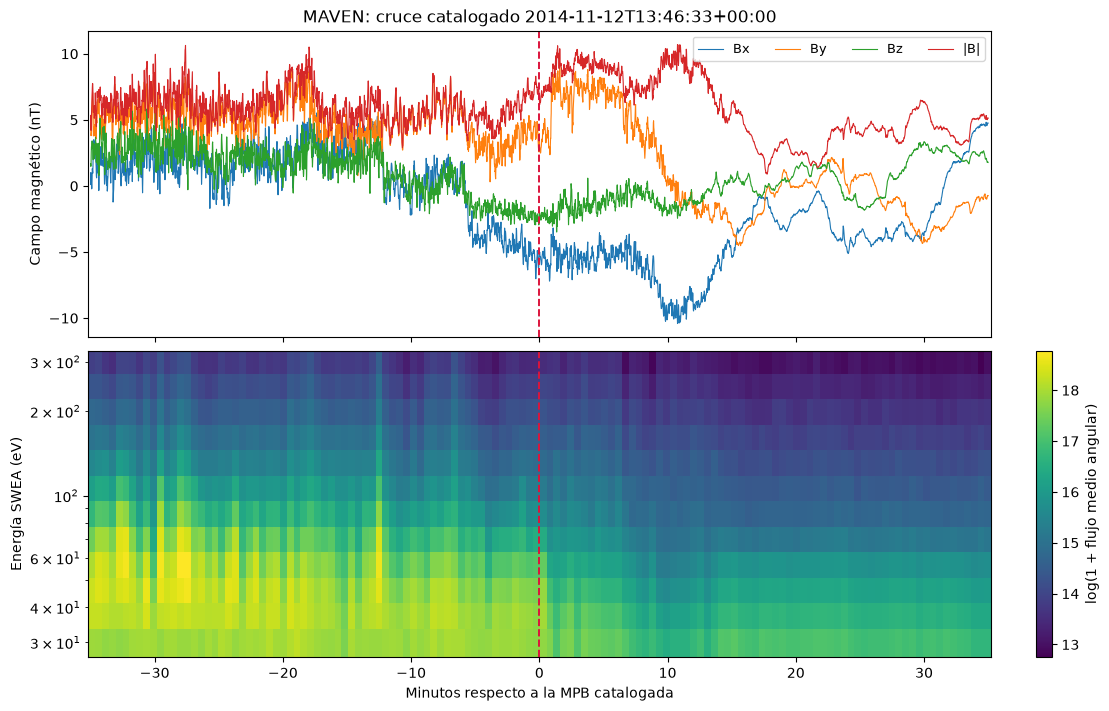

In [5]:
# 2.3 Acceso a las mismas cachés usadas por el entrenamiento.
import importlib.util
TRAIN_PATH = PROJECT_ROOT/'scripts/02_training/01_train_v7b.py'
spec = importlib.util.spec_from_file_location('maven_v7b_trainer',TRAIN_PATH)
trainer = importlib.util.module_from_spec(spec)
spec.loader.exec_module(trainer)

SQL = trainer.query_sources()
cache_mag=MagEventCache(DATA_ROOT/'data/cache/mag_events',project=bq.PROJECT,
                        table=bq.MAG,sql=SQL['MAG'])
cache_swea=SweaEventCache(DATA_ROOT/'data/cache/swea_events',project=bq.PROJECT,
                           table=bq.SWEA+' + '+bq.AXES,sql=SQL['SWEA'])

def load_cached_pair(r):
    start,end=trainer.event_bounds(r)
    m=cache_mag.load(r['time'],start,end,max_rows=25000)
    s=cache_swea.load(r['time'],start,end,max_rows=2000)
    if m is None or s is None or not len(m[0]) or not len(s[0]):
        return None
    return {'MAG':m,'SWEA':s}

def find_cached_event(fold, limit=None):
    eligible=[r for r in rows if r['fold']==fold and r['swea_available']=='1' and r['mag_available']=='1']
    for r in eligible[:limit]:
        pair=load_cached_pair(r)
        if pair is not None and extract_clip(pair['MAG'],pair['SWEA'],r['time'].timestamp()) is not None:
            return r,pair
    return None,None

def plot_cached_observation(row, pair):
    if row is None or pair is None:
        print('Sin caché MAG/SWEA conjunta utilizable: no se simulan mediciones.')
        return
    t0=row['time'].timestamp()
    mt,mx=pair['MAG']; st,sx=pair['SWEA']
    fig,(ax1,ax2)=plt.subplots(2,1,figsize=(11,7),sharex=True,layout='constrained')
    for j,label in enumerate(['Bx','By','Bz','|B|']):
        ax1.plot((mt-t0)/60,mx[:,j],lw=.8,label=label)
    ax1.set(ylabel='Campo magnético (nT)',title=f'MAVEN: cruce catalogado {row["time"].isoformat()}')
    ax1.legend(ncol=4,loc='upper right',fontsize=9)
    im=ax2.pcolormesh((st-t0)/60,ENERGY_EV,sx.T,shading='nearest',cmap='viridis')
    ax2.set(ylabel='Energía SWEA (eV)',xlabel='Minutos respecto a la MPB catalogada',yscale='log')
    fig.colorbar(im,ax=ax2,label='log(1 + flujo medio angular)')
    for ax in (ax1,ax2): ax.axvline(0,c='crimson',ls='--',lw=1.4)
    fig.savefig(FIG_DIR/'03_MAG_SWEA_evento_real.png',dpi=170)
    plt.show()

sample_row,sample_pair=find_cached_event(FOLD_TO_VISUALIZE)
plot_cached_observation(sample_row,sample_pair)


### Identificación de la MPB en las observaciones de MAG y SWEA

El cruce de la *Magnetic Pileup Boundary* (MPB) representa la transición entre la magnetovaina (*magnetosheath*) y la región de acumulación magnética (*Magnetic Pileup Region*, MPR), que forma parte de la magnetosfera inducida de Marte. Esta transición suele manifestarse mediante cambios en las propiedades del campo magnético y de las poblaciones de electrones.

**Campo magnético (MAG)**

En la magnetovaina, el campo magnético suele presentar fluctuaciones importantes debido a la turbulencia del plasma. Al atravesar la MPB hacia la magnetosfera inducida, generalmente se observa un aumento del módulo del campo magnético \(|\mathbf{B}|\), acompañado de una disminución de sus fluctuaciones. También pueden producirse cambios en la orientación del campo, visibles en las componentes \(B_x\), \(B_y\) y \(B_z\).

**Espectro de electrones (SWEA)**

En la magnetovaina se observan electrones supratérmicos asociados al plasma de origen solar. Al ingresar en la magnetosfera inducida, suele producirse una disminución del flujo de estos electrones, especialmente en energías superiores a aproximadamente 70–80 eV. En el espectrograma de SWEA, esta transición puede identificarse como una reducción de la intensidad de los flujos en determinados canales energéticos.

**Interpretación conjunta**

En un cruce de entrada (*inbound*), MAVEN pasa de la magnetovaina a la magnetosfera inducida, por lo que generalmente se espera observar un campo magnético más intenso y menos fluctuante, junto con una disminución del flujo de electrones supratérmicos. En un cruce de salida (*outbound*), estas variaciones suelen producirse en el sentido contrario.

Sin embargo, las características de los cruces pueden variar según las condiciones del viento solar, la geometría de la interacción y la influencia de los campos magnéticos corticales. Por eso, no todos los eventos presentan las mismas firmas ni estas ocurren necesariamente de manera simultánea. La combinación de MAG y SWEA permite identificar las transiciones utilizando información complementaria de ambos instrumentos.

## 3. Entrenamiento mediante ranking de candidatos a la MPB

El *ranking* es una técnica de aprendizaje automático ampliamente utilizada en motores de búsqueda y sistemas de recomendación, donde se busca ordenar diferentes opciones según su relevancia. Decidí incorporar esta estrategia a mi modelo porque, durante las pruebas preliminares, observé una mejora considerable en los resultados de localización temporal de los cruces de la MPB.

La idea principal consiste en entrenar a la red para que no solamente identifique las características de una transición, sino que también aprenda a distinguir las ventanas que contienen un cruce de la MPB de otras ventanas pertenecientes al mismo evento.

### 3.1. Construcción de los candidatos

Para cada cruce de la MPB identificado en el catálogo, construí un conjunto de ventanas temporales de 10 minutos utilizando las mediciones de MAG y SWEA. Estas ventanas están centradas en distintos instantes alrededor del cruce conocido y se clasifican en dos categorías:

- **Candidatos positivos:** consideré tres ventanas, centradas 30 segundos antes, exactamente en el instante catalogado y 30 segundos después del cruce de la MPB. Estas ventanas se etiquetan como positivas porque contienen la transición cerca de su centro.

- **Controles negativos débiles:** seleccioné ventanas centradas a distancias de entre 10 y 30 minutos del cruce, con un espaciamiento de 120 segundos. Para ello, establecí criterios físicos y temporales que permiten excluir ventanas próximas a otras fronteras conocidas, regiones de clasificación ambigua o intervalos con mediciones incompletas.

Denominé *débiles* a estos controles negativos porque su clasificación se infiere a partir de la información del catálogo y no de una inspección individual de las mediciones. Por lo tanto, no puedo garantizar que estén completamente libres de transiciones físicas no catalogadas.

Para los candidatos que cumplen los criterios de selección, también asigné etiquetas aproximadas a las regiones plasmáticas anteriores y posteriores a la ventana, utilizando el orden temporal de los cruces de la MPB y el *bow shock*. En un cruce de entrada, por ejemplo, se espera encontrar magnetovaina antes de la MPB y magnetosfera inducida después. Estas etiquetas se utilizan como información auxiliar durante el entrenamiento.

### 3.2. Formación de los conjuntos de entrenamiento

Una vez construidas las ventanas candidatas, implementé un procedimiento para seleccionar cuáles utilizar en cada época de entrenamiento.

En lugar de generar un conjunto independiente para cada ventana positiva, **formo un único conjunto de candidatos por cada cruce de la MPB catalogado y por cada época de entrenamiento**.

Para cada evento, selecciono hasta seis ventanas:

1. **Dos candidatos positivos**, elegidos aleatoriamente entre las tres ventanas positivas disponibles.
2. **Dos negativos difíciles**, identificados a partir de las puntuaciones obtenidas por el modelo en épocas anteriores.
3. **Dos controles negativos aleatorios**, seleccionados entre las ventanas negativas válidas del mismo evento.

Si no hay suficientes ventanas válidas, el conjunto puede contener menos de seis candidatos. Los eventos que no disponen de al menos un positivo y un negativo válidos no se utilizan para calcular la pérdida de ranking.

De esta manera, cada conjunto contiene diferentes ejemplos correspondientes a un mismo cruce. Las ventanas se procesan individualmente mediante la red neuronal, pero sus puntuaciones se comparan entre sí durante el cálculo de la función de pérdida.

### 3.3. Selección de negativos difíciles

Durante el entrenamiento, algunas ventanas etiquetadas como negativas pueden recibir puntuaciones elevadas de transición MPB. Esto significa que el modelo identifica en ellas características similares a las de los candidatos positivos.

Estas ventanas se denominan **negativos difíciles (*hard negatives*)**.

Para aprovechar esta información, implementé un mecanismo de memoria que registra, para cada evento de entrenamiento, los centros temporales de las ventanas negativas que obtuvieron las puntuaciones más altas.

En épocas posteriores, estas ventanas pueden volver a seleccionarse como negativos difíciles. Al mismo tiempo, incorporo controles negativos aleatorios para que la red continúe explorando otros intervalos y no aprenda únicamente a distinguir un conjunto fijo de ejemplos.

Durante la primera época, cuando todavía no existe información sobre negativos difíciles, completo sus lugares con controles seleccionados aleatoriamente.

Es importante destacar que los negativos difíciles también son negativos débiles. Su etiqueta sigue siendo aproximada; lo que los distingue es que la red les asigna puntuaciones relativamente altas y, por lo tanto, resultan más difíciles de clasificar correctamente.

### 3.4. Comparación de candidatos y función de pérdida

Una vez seleccionado el conjunto de ventanas correspondiente a un evento, la red procesa cada una y calcula una puntuación que representa qué tan compatible resulta con una transición de la MPB.

La función de pérdida de ranking compara **cada candidato positivo con todos los controles negativos seleccionados para ese mismo evento**.

Por ejemplo, si el conjunto contiene dos ventanas positivas y cuatro negativas, realizo ocho comparaciones:

- El primer positivo se compara con los cuatro negativos.
- El segundo positivo también se compara con los cuatro negativos.

Esto no significa que deba ingresar ocho veces las ventanas a la red. Cada ventana se procesa una sola vez y, a partir de las puntuaciones obtenidas, calculo las diferencias correspondientes a los ocho pares.

El objetivo es que las puntuaciones de los candidatos positivos sean mayores que las de los negativos. Para ello, utilizo una función de pérdida de ranking por pares (*pairwise ranking loss*), basada en la función *softplus*, que penaliza las comparaciones en las que la puntuación positiva no supera suficientemente a la negativa.

La función incorpora un margen que establece la separación deseada entre ambas puntuaciones. En este trabajo, el margen seleccionado es de 0,25, aplicado directamente sobre las salidas de la red anteriores a la función sigmoide (*logits*).

Primero calculo la pérdida promedio de todos los pares de un mismo evento y luego promedio las pérdidas de los diferentes eventos del lote. De esta manera, cada evento contribuye con el mismo peso a la pérdida de ranking, independientemente de la cantidad de pares válidos que contenga.

### 3.5. Actualización de los conjuntos entre épocas

Una característica importante de este procedimiento es que **los conjuntos de ventanas no permanecen fijos durante todo el entrenamiento**.

Al comenzar cada época, vuelvo a seleccionar hasta dos candidatos positivos y los controles negativos correspondientes a cada evento. Como la selección de positivos y de parte de los negativos es aleatoria, un mismo cruce puede estar representado por diferentes combinaciones de ventanas a lo largo del entrenamiento.

Por ejemplo, durante una época puedo seleccionar los candidatos positivos centrados en (t\_{\mathrm{MPB}}-30) s y (t\_{\mathrm{MPB}}), mientras que en otra puedo utilizar los centrados en (t\_{\mathrm{MPB}}) y (t\_{\mathrm{MPB}}+30) s.

Algo similar ocurre con los controles negativos: algunos se reutilizan porque la red los identificó como difíciles, mientras que otros se incorporan mediante una nueva selección aleatoria.

Esto también significa que **no utilizo toda la serie temporal en cada época**. Primero construyo un conjunto de ventanas candidatas que cumplen los criterios de selección y, en cada época, utilizo solamente una parte de ellas para actualizar los pesos de la red.

Las ventanas que no fueron seleccionadas en una época pueden incorporarse en épocas posteriores. En cambio, aquellas que no cumplen las condiciones necesarias para asignarles una etiqueta suficientemente confiable quedan excluidas del entrenamiento supervisado.

Este procedimiento permite presentar diferentes combinaciones de ejemplos al modelo sin necesidad de procesar continuamente todas las ventanas posibles de cada evento.

Finalmente, combiné la pérdida de ranking con los otros objetivos del modelo: la clasificación de transiciones, la identificación de las regiones plasmáticas a ambos lados de las ventanas y la reconstrucción de las señales MAG y SWEA.


### Ejemplo real de construcción y comparación de candidatos

La figura siguiente muestra, para un cruce real de la MPB, cómo se construyen las ventanas candidatas a partir de la serie temporal del módulo del campo magnético. En la parte superior se representa un intervalo amplio alrededor del cruce catalogado, mientras que en la parte inferior se muestran ampliaciones de algunas de las ventanas que pueden utilizarse durante el entrenamiento.

Las ventanas centradas en las proximidades del cruce catalogado se consideran candidatos positivos. En cambio, otras ventanas suficientemente alejadas y que cumplen las reglas físicas de exclusión pueden utilizarse como controles negativos débiles.

En la figura posterior se muestra un ejemplo ilustrativo de cómo, en una época de entrenamiento, se selecciona un subconjunto de esas ventanas para formar un conjunto de ranking asociado a un único evento. Allí también se muestran valores de salida de la red y la forma en que se calcula la pérdida de ranking por pares.

/tmp/ipykernel_224513/2479353936.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.96))


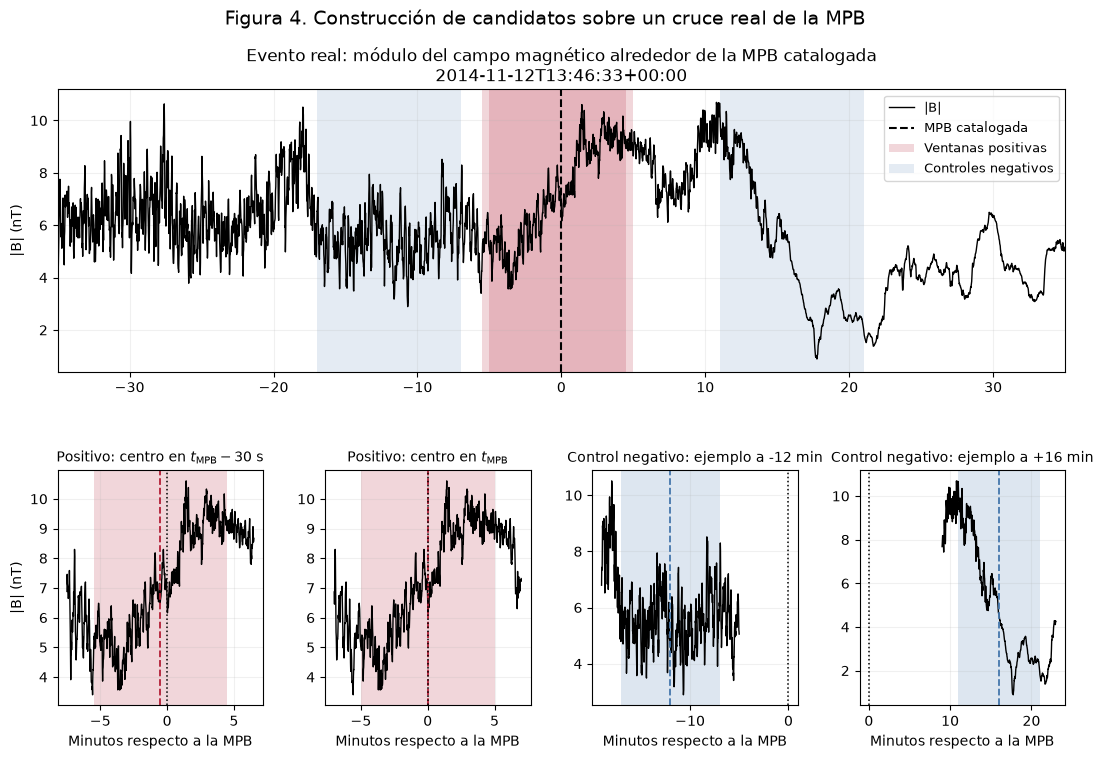

In [6]:
# Figura 4: ejemplo real de construcción de candidatos sobre |B|, de forma consistente.
if sample_row is None or sample_pair is None:
    raise RuntimeError('Primero ejecutá la celda 2.3 para cargar un evento real con MAG y SWEA.')

mt, mx = sample_pair['MAG']
t0 = sample_row['time'].timestamp()
t_rel_min = (mt - t0) / 60.0
bmod = mx[:, 3]

window_halfwidth_min = 5.0  # ventanas de 10 min

# Para que la figura sea clara, muestro exactamente las mismas ventanas arriba y abajo.
candidate_windows = [
    {'title': r'Positivo: centro en $t_{\rm MPB}-30$ s', 'center_s': -30,    'kind': 'positivo', 'color': '#b21e35'},
    {'title': r'Positivo: centro en $t_{\rm MPB}$',      'center_s':   0,    'kind': 'positivo', 'color': '#b21e35'},
    {'title': r'Control negativo: ejemplo a -12 min',   'center_s': -720,   'kind': 'negativo', 'color': '#4577ac'},
    {'title': r'Control negativo: ejemplo a +16 min',   'center_s':  960,   'kind': 'negativo', 'color': '#4577ac'},
]

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(2, 4, height_ratios=[1.2, 1.0], hspace=0.38, wspace=0.30)

# =========================
# Panel principal
# =========================
ax_main = fig.add_subplot(gs[0, :])
ax_main.plot(t_rel_min, bmod, color='black', lw=1.0, label='|B|')

# ÚNICA línea de la MPB catalogada
ax_main.axvline(0, color='black', ls='--', lw=1.5, label='MPB catalogada')

# Sombras de las ventanas elegidas
first_pos = True
first_neg = True
for w in candidate_windows:
    cmin = w['center_s'] / 60.0
    alpha = 0.18 if w['kind'] == 'positivo' else 0.14
    label = None
    if w['kind'] == 'positivo' and first_pos:
        label = 'Ventanas positivas'
        first_pos = False
    if w['kind'] == 'negativo' and first_neg:
        label = 'Controles negativos'
        first_neg = False

    ax_main.axvspan(
        cmin - window_halfwidth_min,
        cmin + window_halfwidth_min,
        color=w['color'],
        alpha=alpha,
        lw=0,
        label=label
    )

ax_main.set(
    xlim=(-35, 35),
    ylabel='|B| (nT)',
    title=f"Evento real: módulo del campo magnético alrededor de la MPB catalogada\n{sample_row['time'].isoformat()}")
ax_main.grid(alpha=0.18)
ax_main.legend(loc='upper right', fontsize=9)

# =========================
# Zooms de las mismas ventanas
# =========================
for j, w in enumerate(candidate_windows):
    ax = fig.add_subplot(gs[1, j])
    cmin = w['center_s'] / 60.0

    mask = (t_rel_min >= cmin - 7) & (t_rel_min <= cmin + 7)
    ax.plot(t_rel_min[mask], bmod[mask], color='black', lw=1.0)

    # ventana usada
    ax.axvspan(
        cmin - window_halfwidth_min,
        cmin + window_halfwidth_min,
        color=w['color'],
        alpha=0.18,
        lw=0
    )

    # centro de la ventana
    ax.axvline(cmin, color=w['color'], ls='--', lw=1.3)

    # MPB catalogada
    ax.axvline(0, color='black', ls=':', lw=1.1)

    ax.set_title(w['title'], fontsize=10)
    ax.set_xlabel('Minutos respecto a la MPB')
    if j == 0:
        ax.set_ylabel('|B| (nT)')
    ax.grid(alpha=0.18)

fig.suptitle('Figura 4. Construcción de candidatos sobre un cruce real de la MPB', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(FIG_DIR/'04_candidatos_evento_real.png', dpi=180, bbox_inches='tight')
plt.show()

/tmp/ipykernel_224513/955496064.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.96))


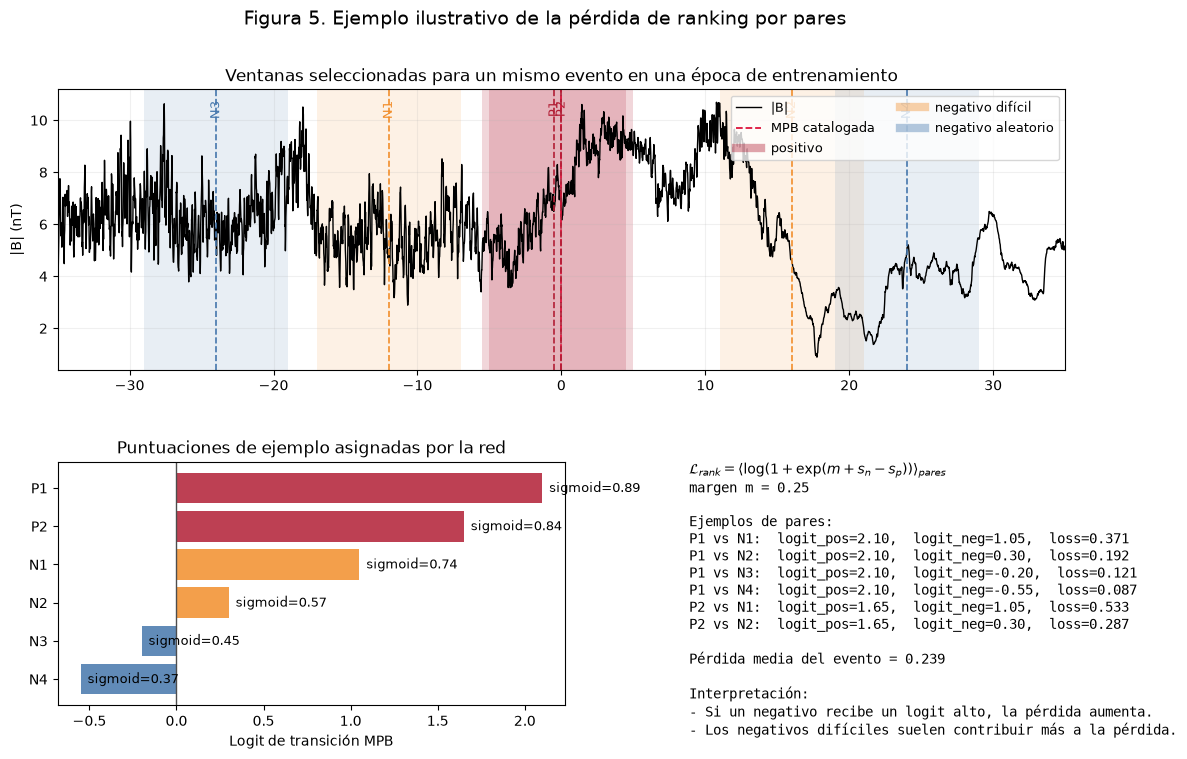

,positivo,negativo,logit_pos,logit_neg,loss_par
0,P1,N1,2.10,1.05,0.371101
1,P1,N2,2.10,0.30,0.192476
2,P1,N3,2.10,-0.20,0.121097
3,P1,N4,2.10,-0.55,0.086836
4,P2,N1,1.65,1.05,0.533382
5,P2,N2,1.65,0.30,0.287335
6,P2,N3,1.65,-0.20,0.183901
7,P2,N4,1.65,-0.55,0.133021


In [7]:
# Figura 5: ejemplo ilustrativo de una iteración de ranking sobre un evento real.
if sample_row is None or sample_pair is None:
    raise RuntimeError('Primero ejecutá la celda 2.3 para cargar un evento real con MAG y SWEA.')

mt, mx = sample_pair['MAG']
t0 = sample_row['time'].timestamp()
t_rel_min = (mt - t0) / 60.0
bmod = mx[:, 3]

# Ejemplo ilustrativo de selección en una época
selected = pd.DataFrame({
    'nombre':    ['P1', 'P2', 'N1', 'N2', 'N3', 'N4'],
    'tipo':      ['positivo', 'positivo',
                  'negativo difícil', 'negativo difícil',
                  'negativo aleatorio', 'negativo aleatorio'],
    'centro_s':  [-30, 0, -12*60, 16*60, -24*60, 24*60],
    'logit':     [2.10, 1.65, 1.05, 0.30, -0.20, -0.55],
})

selected['centro_min'] = selected['centro_s'] / 60.0
selected['score'] = 1.0 / (1.0 + np.exp(-selected['logit']))

margin = 0.25

positives = selected[selected['tipo'] == 'positivo'].copy()
negatives = selected[selected['tipo'] != 'positivo'].copy()

pair_rows = []
for _, prow in positives.iterrows():
    for _, nrow in negatives.iterrows():
        pair_loss = np.log1p(np.exp(margin + nrow['logit'] - prow['logit']))
        pair_rows.append({
            'positivo': prow['nombre'],
            'negativo': nrow['nombre'],
            'logit_pos': prow['logit'],
            'logit_neg': nrow['logit'],
            'loss_par': pair_loss
        })

pairs = pd.DataFrame(pair_rows)
event_rank_loss = pairs['loss_par'].mean()

color_map = {
    'positivo': '#b21e35',
    'negativo difícil': '#f28e2b',
    'negativo aleatorio': '#4577ac',
}

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1.0], width_ratios=[1.35, 1.0],
                      hspace=0.35, wspace=0.28)

# Panel A: |B| con ventanas seleccionadas
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(t_rel_min, bmod, color='black', lw=1.0, label='|B|')
ax1.axvline(0, color='crimson', ls='--', lw=1.3, label='MPB catalogada')

for _, row in selected.iterrows():
    c = color_map[row['tipo']]
    alpha = 0.18 if row['tipo'] == 'positivo' else 0.12
    ax1.axvspan(row['centro_min'] - 5, row['centro_min'] + 5, color=c, alpha=alpha, lw=0)
    ax1.axvline(row['centro_min'], color=c, lw=1.2, ls='--')
    ax1.text(row['centro_min'], ax1.get_ylim()[1]*0.96, row['nombre'],
             color=c, fontsize=9, ha='center', va='top', rotation=90)

for tipo in ['positivo', 'negativo difícil', 'negativo aleatorio']:
    ax1.plot([], [], color=color_map[tipo], lw=6, alpha=0.4, label=tipo)

ax1.set(
    xlim=(-35, 35),
    ylabel='|B| (nT)',
    title='Ventanas seleccionadas para un mismo evento en una época de entrenamiento'
)
ax1.grid(alpha=0.18)
ax1.legend(loc='upper right', fontsize=9, ncol=2)

# Panel B: logits / scores
ax2 = fig.add_subplot(gs[1, 0])
order = selected.sort_values('logit', ascending=True)
bar_colors = [color_map[t] for t in order['tipo']]
ax2.barh(order['nombre'], order['logit'], color=bar_colors, alpha=0.85)
ax2.axvline(0, color='0.3', lw=1.0)
ax2.set_xlabel('Logit de transición MPB')
ax2.set_title('Puntuaciones de ejemplo asignadas por la red')
for y, (_, row) in enumerate(order.iterrows()):
    ax2.text(row['logit'] + 0.04, y,
             f'sigmoid={row["score"]:.2f}',
             va='center', fontsize=9)

# Panel C: tabla resumida de pérdidas por pares
ax3 = fig.add_subplot(gs[1, 1])
ax3.axis('off')

text_lines = [
    r'$\mathcal{L}_{rank}=\langle \log(1+\exp(m+s_n-s_p)) \rangle_{pares}$',
    f'margen m = {margin:.2f}',
    '',
    'Ejemplos de pares:'
]

for _, row in pairs.head(6).iterrows():
    text_lines.append(
        f'{row["positivo"]} vs {row["negativo"]}:  '
        f'logit_pos={row["logit_pos"]:.2f},  '
        f'logit_neg={row["logit_neg"]:.2f},  '
        f'loss={row["loss_par"]:.3f}'
    )

text_lines += [
    '',
    f'Pérdida media del evento = {event_rank_loss:.3f}',
    '',
    'Interpretación:',
    '- Si un negativo recibe un logit alto, la pérdida aumenta.',
    '- Los negativos difíciles suelen contribuir más a la pérdida.'
]

ax3.text(0.0, 1.0, '\n'.join(text_lines), va='top', ha='left',
         fontsize=10, family='monospace')

fig.suptitle('Figura 5. Ejemplo ilustrativo de la pérdida de ranking por pares', fontsize=14, y=0.98)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(FIG_DIR/'05_ejemplo_ranking_loss.png', dpi=180, bbox_inches='tight')
plt.show()

pairs

## 4. Arquitectura de la red neuronal MAG+SWEA

Para localizar los cruces de la MPB desarrollé una red neuronal convolucional que combina las mediciones del campo magnético de MAG con los espectros de electrones de SWEA. La arquitectura está formada por dos ramas independientes, una para cada instrumento, que permiten extraer características de ambas señales antes de combinar su información.

Elegí utilizar esta estructura porque MAG y SWEA miden propiedades físicas diferentes y tienen distintas cadencias temporales. De esta manera, cada instrumento puede procesarse respetando sus tiempos originales, sin necesidad de interpolar una de las series para hacerla coincidir temporalmente con la otra.

### 4.1. Codificadores convolucionales

Cada ventana de entrada tiene una duración de 10 minutos. Para MAG utilizo cuatro canales, correspondientes a las tres componentes del campo magnético ((B_x), (B_y), (B_z)) y su módulo (|\mathbf B|). Para SWEA utilizo 12 canales de energía distribuidos logarítmicamente entre 30 y 300 eV.

Cada instrumento pasa por su propio codificador (*encoder*), compuesto por capas convolucionales unidimensionales y bloques residuales.

**Convolución inicial**

La primera capa de MAG recibe las cuatro series temporales del campo magnético y aplica 24 filtros convolucionales de tamaño 5. Cada filtro combina información de los cuatro canales de entrada y de cinco posiciones temporales para generar una nueva serie de características.

Por lo tanto, la primera convolución transforma los cuatro canales originales en **24 canales internos**, que representan características aprendidas por la red.

Para SWEA realizo una operación equivalente, pero partiendo de los 12 canales energéticos. De esta manera, ambas ramas producen 24 mapas de características temporales después de su primera convolución.

**Bloques residuales**

Después de la convolución inicial incorporé bloques residuales. Un bloque residual consiste en un conjunto de capas que transforma la información de entrada y suma el resultado a la entrada original:

[
y=x+F(x)
]

donde (F(x)) representa la transformación aprendida por las capas convolucionales del bloque.

Esta conexión permite conservar información de las representaciones anteriores y facilita el entrenamiento de redes con varias capas, al favorecer la propagación de los gradientes.

En mi arquitectura, cada bloque residual contiene una convolución de tamaño 5, una función de activación GELU y una convolución de tamaño 1.

**Convoluciones dilatadas**

Las convoluciones dilatadas permiten que los filtros utilicen información de posiciones temporalmente más alejadas sin aumentar la cantidad de parámetros.

En una convolución convencional de tamaño 5, el filtro utiliza cinco posiciones consecutivas. En cambio, con una dilatación (d=2), utiliza cinco posiciones separadas por dos muestras. Si aumento la dilatación a (d=4), utiliza posiciones separadas por cuatro muestras.

Por lo tanto, aunque el filtro sigue utilizando cinco posiciones, el intervalo temporal que puede abarcar aumenta.

En la rama MAG utilizo cuatro bloques residuales con dilataciones de **1, 2, 4 y 8**, mientras que en SWEA utilizo dos bloques con dilataciones de **1 y 2**.

La elección de diferentes dilataciones permite que la red incorpore información de distintas escalas temporales. Esto resulta especialmente útil para identificar tanto variaciones rápidas como cambios más graduales en las propiedades del plasma.

Como las dilataciones se expresan en cantidad de muestras, su alcance temporal depende de la cadencia de cada instrumento.

**Representación latente**

Finalmente, cada codificador utiliza una convolución de tamaño 1 para reducir los 24 canales internos a **16 canales latentes**.

Es importante destacar que estos canales conservan la dimensión temporal de las mediciones. Por lo tanto, no obtengo un único vector de 16 valores por ventana, sino 16 series temporales de características aprendidas para cada instrumento.

Estas representaciones constituyen el espacio latente que analizaré posteriormente para investigar qué características de las señales resultan relevantes para identificar las transiciones de la MPB.

### 4.2. Reconstrucción de las señales

Además de los codificadores, incorporé un decodificador (*decoder*) independiente para cada instrumento.

Su función es reconstruir las señales normalizadas de entrada a partir de las representaciones latentes obtenidas por los codificadores. Para ello, utilizo nuevas capas convolucionales que transforman los 16 canales latentes nuevamente en los cuatro canales de MAG o los 12 de SWEA.

Durante el entrenamiento comparo estas reconstrucciones con las señales originales normalizadas mediante el error cuadrático medio (*Mean Squared Error*, MSE), considerando solamente las muestras temporales válidas.

Incorporé este objetivo de reconstrucción como una tarea auxiliar, con la intención de favorecer que las representaciones latentes conserven información relevante de las señales originales y no solamente aquella necesaria para la clasificación.

Por lo tanto, aunque la arquitectura contiene codificadores y decodificadores similares a los de un autoencoder, **el objetivo principal de la red no es reconstruir las mediciones, sino identificar las transiciones asociadas a la MPB**.

### 4.3. Combinación de las representaciones de MAG y SWEA

Una vez obtenidas las representaciones latentes, necesito combinar la información de ambos instrumentos para determinar si una ventana contiene una transición entre regiones plasmáticas.

Como cada encoder produce 16 series temporales de características, primero debo resumir esa información para obtener una representación de las condiciones del plasma antes y después del centro de la ventana candidata.

**Separación temporal de las representaciones**

Para cada ventana de 10 minutos, considero su centro como (t=0) y divido las representaciones latentes en dos intervalos:

- **Intervalo anterior:** muestras comprendidas entre aproximadamente −300 y −60 segundos respecto del centro.
- **Intervalo posterior:** muestras comprendidas entre aproximadamente +60 y +300 segundos respecto del centro.

De esta manera excluyo las muestras comprendidas entre −60 y +60 segundos del cálculo de los promedios. El objetivo es caracterizar las regiones situadas a ambos lados de la posible transición sin promediar directamente la zona central.

**Promedio temporal de los canales latentes**

Para cada instrumento calculo el promedio temporal de cada uno de sus 16 canales latentes por separado, utilizando únicamente las muestras válidas de cada intervalo.

Por ejemplo, para MAG calculo el promedio del primer canal latente en el intervalo anterior, después el promedio del segundo canal y así sucesivamente hasta completar los 16 canales.

El resultado es un vector de 16 números que resume las características magnéticas anteriores al centro de la ventana.

Repito el procedimiento para el intervalo posterior y obtengo otro vector de 16 componentes.

Realizo exactamente la misma operación con las 16 series latentes de SWEA.

Por lo tanto, para cada ventana obtengo cuatro vectores:

- MAG anterior: 16 componentes.
- MAG posterior: 16 componentes.
- SWEA anterior: 16 componentes.
- SWEA posterior: 16 componentes.

Esta operación permite trabajar con las distintas cadencias temporales de MAG y SWEA, porque cada instrumento se promedia de manera independiente utilizando sus propios tiempos de medición.

**Concatenación de las características**

El siguiente paso consiste en combinar las representaciones de ambos instrumentos mediante una operación de concatenación.

Primero concateno el vector anterior de MAG con el vector anterior de SWEA:

[
\mathbf h\_{\mathrm{izq}}=
[\mathbf z\_{\mathrm{MAG,izq}},
\mathbf z\_{\mathrm{SWEA,izq}}]
]

Como cada vector tiene 16 componentes, obtengo una representación anterior de 32 componentes.

Después realizo la misma operación con las características posteriores:

[
\mathbf h\_{\mathrm{der}}=
[\mathbf z\_{\mathrm{MAG,der}},
\mathbf z\_{\mathrm{SWEA,der}}]
]

De esta manera obtengo otro vector de 32 componentes.

Por lo tanto, cada ventana queda representada por **dos vectores de 32 componentes**: uno que resume las características anteriores y otro que resume las posteriores al centro candidato. Los dos vectores constituyen las entradas para las etapas de clasificación que describo a continuación.

### 4.4. Predicción de las regiones plasmáticas y de la transición

A partir de las representaciones combinadas implementé dos salidas de clasificación.

**Clasificación de regiones plasmáticas**

La primera salida busca distinguir entre la magnetovaina y la magnetosfera inducida.

Para realizar esta clasificación incorporé una pequeña red neuronal completamente conectada, formada por dos capas densas. A diferencia de las capas convolucionales utilizadas anteriormente, una capa densa combina todos los valores de su vector de entrada mediante pesos aprendibles y términos independientes (*bias*).

La primera capa recibe el vector de 32 componentes que resume las características de una región plasmática y lo transforma en otro vector de 32 componentes.

Después aplico la función de activación **GELU**, que introduce una transformación no lineal. Esto permite que la red aprenda relaciones más complejas entre las características magnéticas y electrónicas que una simple combinación lineal.

A continuación incorporé una capa de **dropout** con una probabilidad de 0,15. Durante el entrenamiento, esta capa anula aleatoriamente parte de las activaciones, con el objetivo de reducir la dependencia excesiva de ciertas características y favorecer la generalización del modelo. Durante la evaluación, el dropout se desactiva.

Finalmente, una segunda capa densa transforma los 32 valores resultantes en **un único número**, denominado *logit de región*.

Utilizo **la misma red, con los mismos pesos aprendidos**, para procesar por separado los vectores anteriores y posteriores al centro de la ventana. De esta manera obtengo dos logits de región:

[
s\_{\mathrm{izq}}=f\_{\mathrm{reg}}(\mathbf h\_{\mathrm{izq}})
]

[
s\_{\mathrm{der}}=f\_{\mathrm{reg}}(\mathbf h\_{\mathrm{der}})
]

Estos logits indican qué tan compatibles son las características de cada lado con las dos regiones plasmáticas que quiero distinguir.

Para interpretar sus valores aplico la función sigmoide, que transforma cada logit en una puntuación comprendida entre 0 y 1:

[
P=\sigma(s)=\frac{1}{1+e^{-s}}
]

En mi modelo utilizo la convención de etiquetas **0 para la magnetovaina y 1 para la magnetosfera inducida**. Por lo tanto, cuanto mayor sea la salida de la sigmoide, mayor será la puntuación asignada a la magnetosfera inducida.

**Función de pérdida para la clasificación de regiones**

Durante el entrenamiento comparo las predicciones de la red con las etiquetas aproximadas de las regiones mediante una función denominada **entropía cruzada binaria (*Binary Cross-Entropy*, BCE)**.

Esta función se utiliza para problemas de clasificación con dos clases y mide qué tan bien coinciden las predicciones del modelo con las etiquetas conocidas.

En mi caso, para cada lado de la ventana tengo una etiqueta (y), que puede valer 0 si corresponde a la magnetovaina o 1 si corresponde a la magnetosfera inducida, y una puntuación (p) obtenida a partir del logit de región.

La pérdida se calcula como:

[
\mathcal L\_{\mathrm{BCE}}=
-\left[
y\ln(p)+(1-y)\ln(1-p)
\right]
]

Como la etiqueta solamente puede valer 0 o 1, la expresión se simplifica según la región que quiero identificar.

Si la etiqueta real es magnetosfera inducida ((y=1)):

[
\mathcal L\_{\mathrm{BCE}}=-\ln(p)
]

En este caso, la pérdida disminuye cuando la red asigna una puntuación alta a la magnetosfera inducida y aumenta cuando le asigna una puntuación baja.

Por el contrario, si la etiqueta real es magnetovaina ((y=0)):

[
\mathcal L\_{\mathrm{BCE}}=-\ln(1-p)
]

Ahora la pérdida disminuye cuando la red asigna una puntuación baja a la magnetosfera inducida, es decir, cuando reconoce que las características corresponden a la magnetovaina.

De esta manera, la BCE penaliza especialmente las predicciones incorrectas realizadas con mucha confianza.

Para cada ventana calculo esta pérdida tanto para la región anterior como para la posterior y considero su promedio. Durante el entrenamiento también promedio los resultados de las distintas ventanas del lote.

En la implementación utilizo `BCEWithLogitsLoss` de PyTorch, que calcula esta misma pérdida directamente a partir de los logits, sin necesidad de aplicar explícitamente la función sigmoide. Esta formulación resulta más estable desde el punto de vista numérico.

Con esta tarea auxiliar busco que la red aprenda a reconocer las características de ambos regímenes plasmáticos a partir de la información conjunta de MAG y SWEA.

**Clasificación de la transición MPB**

La segunda salida busca determinar si la ventana contiene una transición compatible con un cruce de la MPB.

Para ello construyo un vector de características que contiene:

1. La representación de la región anterior.
2. La representación de la región posterior.
3. La diferencia entre ambas representaciones.
4. El valor absoluto de esa diferencia.

El vector resultante tiene 128 componentes y pasa por una red de capas densas que devuelve un único logit de transición.

Este logit es la puntuación que utilizo tanto para la clasificación de candidatos como para las comparaciones de ranking explicadas anteriormente.

Para la clasificación de transición también utilizo una pérdida BCE. En este caso, las etiquetas son 1 para las ventanas positivas próximas a un cruce catalogado y 0 para los controles negativos débiles.

Por lo tanto, las dos tareas utilizan el mismo tipo de función de pérdida, pero con objetivos diferentes: una clasifica las regiones plasmáticas a ambos lados de la ventana y la otra clasifica la presencia de una transición MPB cerca de su centro.

La idea es que la red aprenda no solamente las características de cada región, sino también **cómo cambian esas características al atravesar una posible frontera**.

### 4.5. Función de pérdida total

Para entrenar conjuntamente las distintas partes de la arquitectura combiné cuatro objetivos en una única función de pérdida:

[
\mathcal L =
\mathcal L\_{\mathrm{trans}}
+\lambda\_{\mathrm{reg}}\mathcal L\_{\mathrm{reg}}
+\lambda\_{\mathrm{rec}}
\left(\mathcal L\_{\mathrm{MAG}}+\mathcal L\_{\mathrm{SWEA}}\right)
+\lambda\_{\mathrm{rank}}\mathcal L\_{\mathrm{rank}}
]

donde:

- (\mathcal L\_{\mathrm{trans}}) es la pérdida BCE de clasificación binaria de la transición. Compara individualmente los logits de las ventanas candidatas con sus etiquetas positivas o negativas.
- (\mathcal L\_{\mathrm{reg}}) es la pérdida BCE de clasificación de las regiones plasmáticas anteriores y posteriores a cada ventana.
- (\mathcal L\_{\mathrm{MAG}}) y (\mathcal L\_{\mathrm{SWEA}}) corresponden a los errores cuadráticos medios de reconstrucción de las señales normalizadas de cada instrumento.
- (\mathcal L\_{\mathrm{rank}}) es la pérdida de ranking por pares, que busca asignar puntuaciones mayores a los candidatos positivos que a los controles negativos del mismo evento.

Las pérdidas BCE y de ranking cumplen funciones complementarias. Mientras que la BCE evalúa cada clasificación respecto de su etiqueta, el ranking compara las puntuaciones de diferentes ventanas correspondientes al mismo cruce catalogado.

Para las dos tareas de clasificación utilizo BCE calculada directamente a partir de los logits, mientras que para las reconstrucciones utilizo MSE.

Los coeficientes (\lambda) determinan la importancia relativa de cada objetivo durante el entrenamiento. En la configuración seleccionada hasta el momento utilizo:

[
\lambda\_{\mathrm{reg}}=0.5,\qquad
\lambda\_{\mathrm{rec}}=0.15,\qquad
\lambda\_{\mathrm{rank}}=2.
]

Para la función de ranking utilizo además un margen de (m=0.25).

De esta manera, entreno simultáneamente las representaciones de MAG y SWEA para reconstruir las señales, caracterizar las regiones plasmáticas y reconocer las transiciones de la MPB. La pérdida de ranking introduce una comparación adicional entre ventanas de un mismo evento, buscando mejorar la capacidad de discriminación temporal del modelo.


## 5. Entrenamiento: configuración y ejecución reproducible

En las secciones anteriores describí el preprocesamiento de las mediciones, la construcción de los candidatos y la arquitectura de la red neuronal. A continuación explico cómo implementé el entrenamiento del modelo, qué hiperparámetros utilicé y cómo organicé los códigos para que los experimentos puedan reproducirse.

### 5.1. Organización del código

El código completo del proyecto está disponible en el repositorio de GitHub [MAVEN-MPB-DeepLearning](https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning).

Separé la implementación en distintos módulos para evitar repetir código y facilitar las modificaciones y pruebas de cada componente. El notebook funciona principalmente como un informe científico que permite ejecutar los experimentos, visualizar los datos y analizar los resultados.

Los principales archivos son:

| Archivo                                                                                                                                            | Función                                                                                                         |
| -------------------------------------------------------------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------------------------- |
| [`src/model/v7b.py`](https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning/blob/main/src/model/v7b.py)                                       | Define la arquitectura MAG+SWEA, incluidos los encoders, decoders, bloques residuales y redes de clasificación. |
| [`src/model/ranking.py`](https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning/blob/main/src/model/ranking.py)                               | Implementa la pérdida de ranking por pares, la selección de candidatos y la memoria de negativos difíciles.     |
| [`src/preprocessing/weak_regions.py`](https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning/blob/main/src/preprocessing/weak_regions.py)     | Construye las ventanas candidatas y asigna etiquetas débiles de transición y región.                            |
| [`src/preprocessing/native_windows.py`](https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning/blob/main/src/preprocessing/native_windows.py) | Extrae ventanas MAG+SWEA, normaliza los datos y prepara los lotes de entrenamiento.                             |
| [`src/preprocessing/cv_splits.py`](https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning/blob/main/src/preprocessing/cv_splits.py)           | Implementa la separación temporal de los datos de entrenamiento y monitoreo.                                    |
| [`scripts/02_training/01_train_v7b.py`](https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning/blob/main/scripts/02_training/01_train_v7b.py) | Coordina el proceso completo de entrenamiento, monitoreo, guardado de modelos y validación cruzada.             |

También incorporé documentación técnica en la carpeta [`docs/`](https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning/tree/main/docs), donde describo con más detalle la preparación de los datos, la arquitectura, el entrenamiento y los experimentos de hiperparámetros.

### 5.2. Configuración del entrenamiento

Para optimizar los parámetros de la red utilizo el algoritmo **AdamW**, con una tasa de aprendizaje de (3\times10^{-4}) y un coeficiente de regularización `weight_decay=1e-3`.

El algoritmo AdamW adapta las actualizaciones de los parámetros utilizando información de los gradientes obtenidos en iteraciones anteriores. Además, incorpora una penalización sobre los pesos que ayuda a controlar su magnitud durante el entrenamiento.

La configuración exploratoria que utilizo actualmente es:

| Parámetro                               | Valor            |
| --------------------------------------- | ---------------- |
| Optimizador                             | AdamW            |
| Tasa de aprendizaje                     | (3\times10^{-4}) |
| Weight decay                            | (10^{-3})        |
| Tamaño de lote (*batch size*)           | 16               |
| Semilla aleatoria                       | 42               |
| Número máximo de épocas                 | 100              |
| Número mínimo de épocas                 | 10               |
| Paciencia para detención temprana       | 8                |
| Peso de clasificación de regiones       | 0,5              |
| Peso de reconstrucción                  | 0,15             |
| Peso de ranking                         | 2                |
| Margen de ranking                       | 0,25             |
| Espaciamiento de controles negativos    | 120 s            |
| Candidatos positivos por evento y época | Hasta 2          |
| Negativos difíciles por evento y época  | Hasta 2          |
| Negativos aleatorios por evento y época | Hasta 2          |
| Paso temporal de evaluación             | 32 s             |

Para estudiar los hiperparámetros desarrollé códigos independientes dentro de [`scripts/03_experiments/`](https://github.com/CamilaMastronardi/MAVEN-MPB-DeepLearning/tree/main/scripts/03_experiments), que permiten comparar diferentes pesos de ranking, márgenes y pesos de clasificación de regiones.

### 5.3. Procedimiento de entrenamiento

El procedimiento principal está implementado en `scripts/02_training/01_train_v7b.py`.

Para cada fold, el programa realiza las siguientes operaciones:

1. **Carga de datos:** leo los cruces catalogados y recupero las mediciones MAG y SWEA desde las cachés disponibles. Si faltan datos, el programa puede consultarlos en BigQuery.

2. **Separación de los datos:** distingo los eventos destinados al entrenamiento de aquellos reservados para la validación externa. Dentro del conjunto de entrenamiento separo los subconjuntos FIT y MONITOR, agrupados temporalmente por meses.

3. **Normalización:** calculo los parámetros de normalización utilizando exclusivamente las mediciones correspondientes a FIT. Aplico esos parámetros a las ventanas utilizadas posteriormente, sin recalcularlos con los datos de MONITOR o validación externa.

4. **Construcción de candidatos:** genero las ventanas positivas y los controles negativos débiles siguiendo los criterios físicos explicados en la sección 3.

5. **Selección por época:** construyo los conjuntos de ranking correspondientes a cada evento. La selección se actualiza entre épocas mediante candidatos positivos, controles negativos aleatorios y negativos difíciles obtenidos durante el entrenamiento.

6. **Propagación hacia adelante (*forward pass*):** ingreso los lotes de ventanas a la red MAG+SWEA, que calcula las reconstrucciones de ambos instrumentos, los logits de clasificación de regiones y los logits de transición.

7. **Cálculo de la pérdida:** combino los errores de clasificación, reconstrucción y ranking mediante la función de pérdida total presentada en la sección 4.

8. **Actualización de los pesos:** calculo los gradientes de la pérdida mediante retropropagación (*backpropagation*) y utilizo AdamW para actualizar los parámetros entrenables.

Estas operaciones se repiten durante las distintas épocas, modificando progresivamente los parámetros de la red para reducir la función de pérdida.

En el código, la función `train_epoch()` ejecuta una época de entrenamiento, mientras que `classification_losses()` calcula las pérdidas de clasificación y reconstrucción. La función de ranking se calcula mediante `event_pairwise_ranking_loss()`, definida en `src/model/ranking.py`.

### 5.4. Monitoreo y detención temprana

Para evitar entrenar durante más épocas de las necesarias, implementé un procedimiento de **detención temprana (*early stopping*)**.

Después de cada época evalúo el modelo utilizando MONITOR, un subconjunto de eventos separado de FIT y que no se utiliza para actualizar los pesos mediante gradientes.

Para seleccionar el mejor modelo utilizo una función de monitoreo que combina la pérdida de clasificación de transición, la pérdida de clasificación de regiones y la pérdida de ranking:

[
\mathcal L\_{\mathrm{monitor}}=
\mathcal L\_{\mathrm{trans}}
+0.5,\mathcal L\_{\mathrm{reg}}
+2,\mathcal L\_{\mathrm{rank}}
]

A diferencia de la función de pérdida total utilizada para entrenar, **esta función de selección no incluye los errores de reconstrucción**.

Establecí un mínimo de 10 épocas y una paciencia de 8. Esto significa que, una vez alcanzada la cantidad mínima de épocas, si la función de monitoreo no presenta una mejora suficiente durante ocho épocas consecutivas, detengo el entrenamiento.

El programa conserva el modelo correspondiente al mejor valor de la función de monitoreo, en lugar de utilizar necesariamente los parámetros obtenidos en la última época.

Este procedimiento se implementa dentro de `fold_training()` y utiliza `monitor_epoch()` para calcular las pérdidas sobre MONITOR.

### 5.5. Ejecución reproducible y almacenamiento de resultados

Para facilitar la reproducción de los experimentos, centralicé la configuración en la celda **1.2. Configuración central** del notebook.

Allí defino los hiperparámetros mediante la clase `Config` y controlo la ejecución con las variables `RUN_TRAINING` y `PILOT_EVENTS_PER_FOLD`.

La celda **5.1. Autenticación opcional y entrenamiento real** prepara automáticamente el comando que ejecuta el script principal, utilizando los parámetros definidos anteriormente. De esta manera, no necesito ejecutar manualmente cada módulo del proyecto.

Por seguridad, inicialmente establecí:

```python
RUN_TRAINING = False
PILOT_EVENTS_PER_FOLD = 0
```

Con `RUN_TRAINING=False`, el notebook no inicia un nuevo entrenamiento. Si existen resultados completos compatibles con la configuración, las secciones posteriores pueden reutilizarlos para realizar los análisis.

Para ejecutar un entrenamiento nuevo debo cambiar `RUN_TRAINING=True`. El programa puede trabajar con observaciones previamente almacenadas en caché y consultar los datos faltantes desde BigQuery, siempre que tenga las credenciales necesarias.

Antes de realizar consultas faltantes, el script estima mediante *dry runs* el volumen de datos que sería procesado y verifica los límites configurados. Esto permite controlar el uso de recursos y reducir consultas innecesarias.

Los resultados se guardan localmente en la carpeta `results/metrics/`. Para cada fold conservo los parámetros finales del modelo, el historial de entrenamiento y las métricas correspondientes. También genero un archivo `cv_summary.json` que reúne los resultados principales de la validación cruzada.

En la siguiente sección analizaré la evolución de las funciones de pérdida y las métricas obtenidas, con el objetivo de evaluar el comportamiento del modelo y su capacidad para localizar temporalmente los cruces catalogados de la MPB.


In [8]:
# 5.1 Autenticación opcional y entrenamiento REAL (sin datos inventados).
# Este comando usa exactamente las mismas funciones de preprocessing, CNN y CV del proyecto.
def check_cloud_auth():
    try:
        import google.auth
        google.auth.default(scopes=['https://www.googleapis.com/auth/cloud-platform'])
        return
    except Exception:
        try:
            from google.colab import auth
            print('Solicitando autorización Colab para BigQuery...')
            auth.authenticate_user()
        except ImportError as exc:
            raise RuntimeError('No hay credenciales ADC. Configurar gcloud auth application-default login.') from exc

training_cmd = [sys.executable,'-u',str(TRAIN_PATH),
                '--folds','all','--pilot-events-per-fold',str(PILOT_EVENTS_PER_FOLD),
                '--manifest',str(MANIFEST),
                '--output-dir',str(OUT_DIR),
                '--mag-cache-dir',str(DATA_ROOT/'data/cache/mag_events'),
                '--swea-cache-dir',str(DATA_ROOT/'data/cache/swea_events'),
                '--rank-weight',str(CFG.rank_weight), '--rank-margin',str(CFG.rank_margin),
                '--region-weight',str(CFG.region_weight),
                '--reconstruction-weight',str(CFG.reconstruction_weight),
                '--learning-rate',str(CFG.learning_rate),
                '--batch-size',str(CFG.batch_size), '--seed',str(CFG.seed),
                '--max-epochs',str(CFG.max_epochs), '--min-epochs',str(CFG.min_epochs),
                '--patience',str(CFG.patience),
                '--rank-control-step-s',str(CFG.rank_control_step_s),
                '--rank-positives-per-event',str(CFG.rank_positives_per_event),
                '--rank-hard-negatives',str(CFG.rank_hard_negatives),
                '--rank-random-negatives',str(CFG.rank_random_negatives),
                '--evaluation-stride-s',str(CFG.evaluation_stride_s),
                '--torch-threads',str(TORCH_THREADS), '--resume','--execute']
if RUN_TRAINING:
    # Si la corrida de referencia ya está terminada, evitar 4 entrenamientos idénticos.
    # Se comprueba la configuración antes de omitir, no solo la existencia del archivo.
    reference = DATA_ROOT/'results/metrics/v7b_ranking_margin_sweep/margin_0p25'
    ref_summary = reference/'cv_summary.json'
    reuse_existing = False
    if PILOT_EVENTS_PER_FOLD == 0 and ref_summary.is_file():
        meta = json.loads(ref_summary.read_text())
        opts = meta.get('training_configuration', {})
        expected = {'rank_weight': CFG.rank_weight, 'rank_margin': CFG.rank_margin,
                    'region_weight': CFG.region_weight,
                    'reconstruction_weight': CFG.reconstruction_weight,
                    'seed': CFG.seed, 'learning_rate': CFG.learning_rate,
                    'batch_size': CFG.batch_size, 'max_epochs': CFG.max_epochs,
                    'manifest_sha256': hashlib.sha256(MANIFEST.read_bytes()).hexdigest()}
        reuse_existing = (all(opts.get(k) == v for k,v in expected.items())
            and meta.get('pilot_subset') is False
            and sorted(meta.get('completed_folds', [])) == [1,2,3,4]
            and all((reference/f'fold_{k:02d}_final.pt').is_file()
                    and (reference/f'fold_{k:02d}_metrics.json').is_file()
                    and (reference/f'fold_{k:02d}_event_metrics.csv').is_file()
                    for k in range(1,5)))
    if reuse_existing:
        print('Ya existe una corrida completa compatible:',reference)
        print('Se reutilizará para figuras y PCA; no se reentrena.')
    else:
        # Las credenciales son necesarias si la cache no está completa; se comprueban
    # antes de lanzar cualquier extracción física potencialmente facturable.
        try:
            import google.colab
        except ImportError:
            pass  # WSL/local: los datos pueden estar completamente en caché.
        else:
            check_cloud_auth()
        OUT_DIR.mkdir(parents=True,exist_ok=True)
        subprocess.run(training_cmd,cwd=PROJECT_ROOT,check=True)
else:
    print('Entrenamiento desactivado; para ejecutarlo poner RUN_TRAINING=True.')
    print('Comando preparado:\n', ' '.join(training_cmd))


Entrenamiento desactivado; para ejecutarlo poner RUN_TRAINING=True.
Comando preparado:
 /home/cami/Codigos/MAVEN-MPB-DeepLearning/.venv/bin/python -u /home/cami/Codigos/MAVEN-MPB-DeepLearning/scripts/02_training/01_train_v7b.py --folds all --pilot-events-per-fold 0 --manifest /home/cami/Codigos/MAVEN-MPB-DeepLearning/data/splits/cv4_monthly_manifest.csv --output-dir /home/cami/Codigos/MAVEN-MPB-DeepLearning/results/metrics/v7b_notebook_rank2_margin0p25_region0p5 --mag-cache-dir /home/cami/Codigos/MAVEN-MPB-DeepLearning/data/cache/mag_events --swea-cache-dir /home/cami/Codigos/MAVEN-MPB-DeepLearning/data/cache/swea_events --rank-weight 2.0 --rank-margin 0.25 --region-weight 0.5 --reconstruction-weight 0.15 --learning-rate 0.0003 --batch-size 16 --seed 42 --max-epochs 100 --min-epochs 10 --patience 8 --rank-control-step-s 120 --rank-positives-per-event 2 --rank-hard-negatives 2 --rank-random-negatives 2 --evaluation-stride-s 32 --torch-threads 2 --resume --execute


## 6. Evaluación del modelo y error de localización de la MPB

Una vez finalizado el entrenamiento, utilizo la red neuronal para estimar el instante de cruce de la MPB en los eventos del fold reservado para validación externa. Estos eventos no se utilizaron para actualizar los pesos ni para seleccionar el mejor modelo durante el entrenamiento.

Como implementé una validación cruzada de cuatro folds, repito este procedimiento cuatro veces. En cada repetición entreno un modelo utilizando los eventos de tres folds, selecciono el mejor checkpoint mediante MONITOR y evalúo su capacidad de localización sobre el fold restante.

### 6.1. Localización temporal de la MPB

Para cada evento de validación conozco el instante de cruce de la MPB indicado en el catálogo, \(t_{\mathrm{MPB}}\). Utilizo este instante exclusivamente para definir el intervalo de búsqueda y, posteriormente, calcular el error de localización. **El instante catalogado no se introduce como una característica de entrada de la red neuronal.**

El procedimiento de evaluación consta de las siguientes etapas:

**1. Construcción de las ventanas candidatas**

Para cada cruce catalogado considero un intervalo temporal de 60 minutos, comprendido entre 30 minutos antes y 30 minutos después del instante de referencia:

\[
[t_{\mathrm{MPB}}-1800\,\mathrm{s},\;
t_{\mathrm{MPB}}+1800\,\mathrm{s}]
\]

Dentro de este intervalo genero centros candidatos separados por 32 segundos. Para cada centro extraigo una ventana de 10 minutos de mediciones MAG y SWEA, utilizando cinco minutos anteriores y cinco posteriores.

Las mediciones de ambos instrumentos conservan sus cadencias temporales originales, y solamente evalúo las ventanas que cumplen los criterios de disponibilidad y calidad de los datos.

**2. Aplicación de la red neuronal entrenada**

Cada ventana candidata se introduce en la red MAG+SWEA utilizando los parámetros de normalización calculados previamente con FIT y los pesos del mejor checkpoint seleccionado durante MONITOR.

Durante esta etapa no actualizo los parámetros de la red ni calculo gradientes.

Como describí en la sección 4, la arquitectura contiene dos ramas de clasificación: una que identifica las regiones plasmáticas anteriores y posteriores al centro de la ventana y otra que determina si las características observadas son compatibles con una transición de la MPB.

**Para localizar el cruce utilizo exclusivamente el logit producido por la red de clasificación de transición.**

Para la ventana candidata \(i\), represento esta salida mediante:

\[
s_i=f_{\theta}(X_{\mathrm{MAG},i},X_{\mathrm{SWEA},i})
\]

donde \(f_{\theta}\) representa la red neuronal entrenada, \(\theta\) corresponde a sus parámetros aprendidos y \(X_{\mathrm{MAG},i}\) y \(X_{\mathrm{SWEA},i}\) son las mediciones de la ventana candidata. En la implementación también utilizo las máscaras temporales y los tiempos relativos de cada instrumento.

El logit \(s_i\) es un número real que expresa la compatibilidad de la ventana con una transición MPB según las características aprendidas por el modelo.

Para convertirlo en una puntuación entre 0 y 1 aplico la función sigmoide:

\[
p_i=\sigma(s_i)=\frac{1}{1+e^{-s_i}}
\]

De esta manera, obtengo una puntuación de transición para cada ventana candidata.

**3. Selección del instante estimado**

Una vez evaluadas todas las ventanas válidas, selecciono aquella que presenta la mayor puntuación de transición:

\[
i^*=\operatorname*{arg\,max}_i p_i
\]

Como cada ventana está asociada a un instante central \(t_i\), defino el instante estimado de cruce de la MPB como:

\[
\boxed{\hat t_{\mathrm{MPB}}=t_{i^*}}
\]

Por lo tanto, el modelo no estima directamente un tiempo continuo dentro de cada ventana, sino que selecciona el centro de la ventana que considera más compatible con una transición MPB.

La resolución temporal de esta búsqueda está determinada por el espaciamiento de 32 segundos entre centros candidatos.

Es importante destacar que, en la implementación actual, selecciono la ventana con la mayor puntuación siempre que existan candidatos válidos. No exijo que esa puntuación supere un umbral mínimo para aceptar la localización.

**4. Cálculo del error temporal**

Finalmente, comparo el instante estimado por la red con el instante de referencia del catálogo.

Para cada evento \(j\) defino el error absoluto de localización como:

\[
\boxed{
\epsilon_j=
\left|
\hat t_{\mathrm{MPB},j}
-t_{\mathrm{MPB},j}
\right|
}
\]

Este error se expresa en segundos y representa la diferencia temporal entre la predicción del modelo y el cruce catalogado.

Por ejemplo, si el catálogo indica una MPB a las 12:00:00 y la red selecciona una ventana centrada a las 12:00:56, el error absoluto de localización es de 56 segundos.

### 6.2. Métricas de evaluación

Después de evaluar los eventos de los cuatro folds, reúno los errores absolutos de los cruces para los cuales fue posible construir al menos una ventana MAG+SWEA válida.

A partir de estos errores calculo:

- **Mediana del error absoluto:** indica el error por debajo del cual se encuentra el 50 % de los eventos evaluables.
- **Percentil 90 del error absoluto:** representa el error por debajo del cual se encuentra el 90 % de esos eventos.
- **Fracción de eventos con error menor o igual a 60 segundos:** cuantifica la proporción de cruces localizados dentro de un minuto del instante catalogado.
- **Fracción de eventos con error menor o igual a 120 segundos:** cuantifica la proporción localizada dentro de dos minutos.
- **Cantidad de eventos evaluables:** permite identificar cuántos cruces pudieron analizarse efectivamente con los datos disponibles.

También conservo las métricas de clasificación de candidatos y regiones plasmáticas obtenidas a partir de las etiquetas débiles. Estas métricas son complementarias al error temporal de localización.

**Limitación del procedimiento**

La evaluación que implementé es una evaluación de localización condicionada: para cada evento conozco previamente que existe una MPB catalogada en el intervalo de búsqueda.

Por lo tanto, los resultados permiten estudiar qué tan cerca del instante catalogado puede localizar la frontera la red neuronal, pero no demuestran todavía su capacidad para detectar de manera autónoma todas las MPB presentes en una órbita completa.

Para evaluar esa capacidad sería necesario aplicar el modelo sobre series continuas, sin definir previamente intervalos alrededor de cruces conocidos, y establecer un criterio para distinguir detecciones reales de falsos positivos.

En la siguiente celda recupero los resultados de los entrenamientos compatibles con la configuración seleccionada y calculo las métricas de localización temporal correspondientes a los cuatro folds.

In [9]:

# 6.1 Selección de resultados existentes y tabla de métricas.
# No sobrescribir "rows", que contiene los eventos del catálogo MPB.

# Recuperar el catálogo si "rows" fue sobrescrita por otra celda.
if not rows or 'time' not in rows[0]:
    from src.preprocessing.catalog import read_manifest

    rows = read_manifest(MANIFEST)
    for r in rows:
        r['bs_time'] = bq.to_utc(r['bs_timestamp_utc'])

    print('Catálogo MPB recuperado:', len(rows), 'eventos')


if RUN_TRAINING and sample_pair is None:
    sample_row, sample_pair = find_cached_event(FOLD_TO_VISUALIZE)
    plot_cached_observation(sample_row, sample_pair)

import csv


def valid_results(folder):
    summary_path = folder / 'cv_summary.json'

    if not summary_path.is_file():
        return False

    summary = json.loads(summary_path.read_text())
    conf = summary.get('training_configuration', {})

    expected = {
        'rank_weight': CFG.rank_weight,
        'rank_margin': CFG.rank_margin,
        'region_weight': CFG.region_weight,
        'reconstruction_weight': CFG.reconstruction_weight,
        'seed': CFG.seed,
        'learning_rate': CFG.learning_rate,
        'batch_size': CFG.batch_size,
        'max_epochs': CFG.max_epochs,
        'evaluation_stride_s': CFG.evaluation_stride_s,
        'manifest_sha256': hashlib.sha256(
            MANIFEST.read_bytes()
        ).hexdigest()
    }

    if any(conf.get(k) != v for k, v in expected.items()):
        return False

    if summary.get('pilot_subset') != bool(PILOT_EVENTS_PER_FOLD):
        return False

    return all(
        (folder / f'fold_{k:02d}_metrics.json').is_file()
        and (folder / f'fold_{k:02d}_final.pt').is_file()
        and (folder / f'fold_{k:02d}_event_metrics.csv').is_file()
        for k in range(1, 5)
    )


# --------------------------------------------------
# Buscar resultados compatibles
# --------------------------------------------------

runs = [
    OUT_DIR,
    DATA_ROOT / 'results/metrics/v7b_ranking_margin_sweep/margin_0p25',
    DATA_ROOT / 'results/metrics/v7b_region_weight_sweep/region_0p5'
]

if os.environ.get('MAVEN_V7B_EXISTING_RESULTS'):
    runs.insert(
        0,
        Path(
            os.environ['MAVEN_V7B_EXISTING_RESULTS']
        ).expanduser()
    )

run_dir = next(
    (p for p in runs if valid_results(p)),
    None
)


if run_dir is None:
    print(
        'No hay una CV completa compatible. '
        'Ejecutá la celda de entrenamiento o configurá '
        'MAVEN_V7B_EXISTING_RESULTS.'
    )

else:
    print('Resultados compatibles:', run_dir)

    # --------------------------------------------------
    # Cargar resultados de los cuatro folds
    # --------------------------------------------------

    fold_metrics = {
        k: json.loads(
            (run_dir / f'fold_{k:02d}_metrics.json').read_text()
        )
        for k in range(1, 5)
    }

    all_events = pd.concat(
        [
            pd.read_csv(
                run_dir / f'fold_{k:02d}_event_metrics.csv'
            ).assign(fold=k)
            for k in range(1, 5)
        ],
        ignore_index=True
    )

    all_events['absolute_error_s'] = pd.to_numeric(
        all_events['absolute_error_s'],
        errors='coerce'
    )

    errs = (
        all_events['absolute_error_s']
        .dropna()
        .to_numpy()
    )

    # --------------------------------------------------
    # Calcular métricas por fold y globales
    # --------------------------------------------------

    def calculate_metrics(df, name):
        errors = (
            df['absolute_error_s']
            .dropna()
            .to_numpy()
        )

        n = len(errors)

        return {
            'Conjunto': name,
            'Eventos totales': len(df),
            'Evaluables': n,
            'Mediana (s)': np.median(errors) if n else np.nan,
            'P90 (s)': np.percentile(errors, 90) if n else np.nan,
            'Error ≤ 60 s': np.mean(errors <= 60) if n else np.nan,
            'Error ≤ 120 s': np.mean(errors <= 120) if n else np.nan
        }

    # Usar otro nombre para no sobrescribir los eventos.
    metrics_rows = []

    for k in range(1, 5):
        fold_data = all_events[
            all_events['fold'] == k
        ]

        metrics_rows.append(
            calculate_metrics(fold_data, f'Fold {k}')
        )

    metrics_rows.append(
        calculate_metrics(all_events, 'TOTAL')
    )

    metrics_table = pd.DataFrame(
        metrics_rows
    ).set_index('Conjunto')

    # --------------------------------------------------
    # Mostrar tabla
    # --------------------------------------------------

    display(
        metrics_table.style.format(
            {
                'Eventos totales': '{:.0f}',
                'Evaluables': '{:.0f}',
                'Mediana (s)': '{:.1f}',
                'P90 (s)': '{:.1f}',
                'Error ≤ 60 s': '{:.1%}',
                'Error ≤ 120 s': '{:.1%}'
            },
            na_rep='—'
        ).set_caption(
            'Resultados de localización temporal de la MPB'
        )
    )

# Verificar que el catálogo original siga disponible.
print('Eventos disponibles en el catálogo:', len(rows))


Resultados compatibles: /home/cami/Codigos/MAVEN-MPB-DeepLearning/results/metrics/v7b_ranking_margin_sweep/margin_0p25


,Eventos totales,Evaluables,Mediana (s),P90 (s),Error ≤ 60 s,Error ≤ 120 s
Conjunto,,,,,,
Fold 1,146,146,72.0,360.0,48.6%,71.2%
Fold 2,139,139,72.0,516.8,43.9%,68.3%
Fold 3,135,135,72.0,504.0,43.7%,65.9%
Fold 4,139,139,104.0,651.2,33.8%,56.8%
TOTAL,559,559,72.0,552.0,42.6%,65.7%


Eventos disponibles en el catálogo: 569


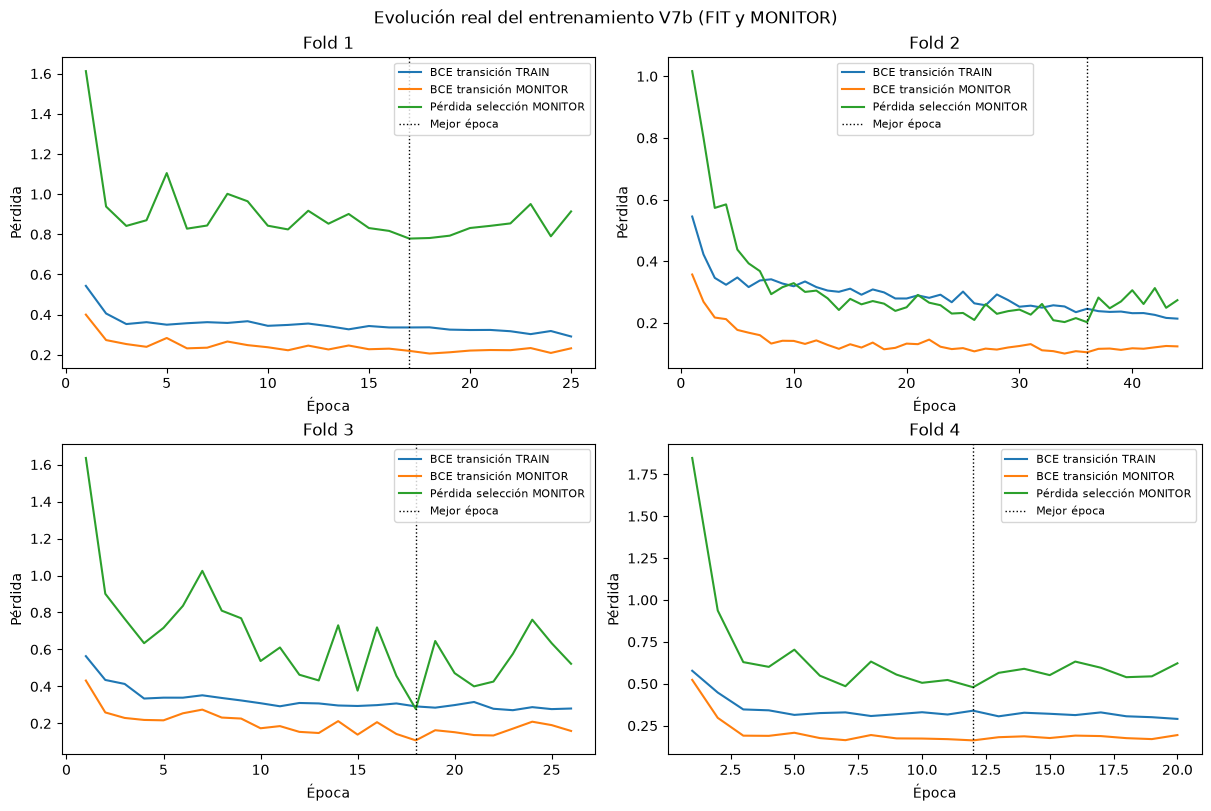

In [10]:
# 6.2 Curvas de pérdidas y monitor. Traza valores observados de los 4 folds.
if run_dir is not None:
    fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
    for k,ax in enumerate(axes.flat,1):
        h=pd.DataFrame(fold_metrics[k]['train_history'])
        if h.empty:
            ax.text(.5,.5,'Sin historial',transform=ax.transAxes,ha='center')
            continue
        ax.plot(h['epoch'],h['train_det'],label='BCE transición TRAIN')
        ax.plot(h['epoch'],h['val_det'],label='BCE transición MONITOR')
        ax.plot(h['epoch'],h['val_select'],label='Pérdida selección MONITOR')
        ax.axvline(fold_metrics[k]['best_epoch'],color='k',ls=':',lw=1,label='Mejor época')
        ax.set(xlabel='Época',ylabel='Pérdida',title=f'Fold {k}')
        ax.legend(fontsize=8)
    fig.suptitle('Evolución real del entrenamiento V7b (FIT y MONITOR)')
    fig.savefig(FIG_DIR/'06_curvas_entrenamiento.png',dpi=170);plt.show()
else:
    print('Curvas no disponibles sin resultados compatibles.')


### Análisis de la evolución del entrenamiento

En la figura anterior presento la evolución de las funciones de pérdida durante el entrenamiento de los cuatro folds. Para cada uno represento la pérdida BCE de clasificación de transición calculada sobre FIT y MONITOR, junto con la función de pérdida utilizada para seleccionar el mejor modelo. La línea vertical punteada indica la época en la que obtuve el menor valor de esta última función y, por lo tanto, el checkpoint seleccionado.

En primer lugar, observo que **la pérdida BCE de transición disminuye durante las primeras épocas en los cuatro folds**, tanto para FIT como para MONITOR. Esto indica que, durante las etapas iniciales del entrenamiento, la red mejora su capacidad para distinguir las ventanas positivas de los controles negativos utilizados en la clasificación.

Sin embargo, las curvas correspondientes a FIT y MONITOR presentan comportamientos diferentes. En particular, la BCE de transición de MONITOR es sistemáticamente menor que la de FIT. Esta diferencia no implica necesariamente un problema en el entrenamiento, ya que ambos conjuntos contienen diferentes eventos y no se construyen exactamente con la misma selección de candidatos. Además, la evaluación de MONITOR se realiza con el modelo en modo evaluación, sin dropout.

Es importante distinguir estas curvas de la función de pérdida de selección, representada en verde. Esta última combia tres contribuciones:

\[
\mathcal L_{\mathrm{monitor}}
=
\mathcal L_{\mathrm{trans}}
+
0.5\,\mathcal L_{\mathrm{reg}}
+
2\,\mathcal L_{\mathrm{rank}}
\]

Por lo tanto, su valor no debe compararse directamente con el de la BCE de transición, ya que también incorpora la clasificación de regiones plasmáticas y el ranking de candidatos. Además, no incluye el error de reconstrucción de MAG y SWEA, que sí interviene durante el entrenamiento.

**Comparación entre los folds**

En el **fold 1**, observo una disminución pronunciada de la pérdida de selección durante las primeras épocas, seguida de oscilaciones relativamente importantes. El mínimo se alcanza aproximadamente en la época 17. A partir de ese momento, la pérdida deja de mejorar de manera sostenida, aunque la BCE de transición permanece relativamente estable.

En el **fold 2**, la disminución de la pérdida de selección es más gradual y sostenida. El mínimo se alcanza aproximadamente en la época 35, por lo que este fold requiere una mayor cantidad de épocas para seleccionar su mejor modelo. Tanto la BCE de transición de FIT como la de MONITOR muestran una tendencia general descendente, aunque con pequeñas fluctuaciones.

En el **fold 3**, la pérdida de selección presenta oscilaciones más marcadas, especialmente durante las primeras épocas. El mínimo se encuentra aproximadamente en la época 18. Posteriormente aparecen nuevos aumentos y disminuciones, pero no se alcanza un valor inferior al mínimo previamente obtenido.

Finalmente, en el **fold 4** observo una disminución rápida de las pérdidas durante las primeras épocas. La pérdida de selección alcanza su mínimo aproximadamente en la época 12 y luego comienza a aumentar, mientras que la BCE de transición se mantiene relativamente estable. Este comportamiento muestra que una mejora sostenida de la clasificación de transición no necesariamente implica una mejora de la función de selección completa.

**Detención temprana y selección de los modelos**

La selección de los checkpoints se realiza utilizando la función de pérdida de MONITOR, sin utilizar los eventos del fold externo de validación y utilizando detección temprana de 8 epocas. 

Las diferencias entre las épocas seleccionadas muestran que **no todos los folds presentan la misma dinámica de aprendizaje**. Esto puede estar relacionado con las distintas características físicas de los eventos, la distribución de los candidatos y las diferencias entre los conjuntos utilizados para entrenar y monitorear cada modelo.

Por otra parte, las oscilaciones de la pérdida de selección indican que el comportamiento de la red no depende exclusivamente de la clasificación binaria de las ventanas, sino también de su capacidad para caracterizar las regiones plasmáticas y asignar puntuaciones relativas adecuadas mediante el ranking.

En conjunto, las curvas muestran que el procedimiento de entrenamiento permite disminuir las pérdidas iniciales y seleccionar un checkpoint para cada fold sin recurrir a la validación externa. Sin embargo, **la disminución de estas funciones de pérdida no garantiza por sí sola una buena localización temporal de la MPB**.

Para determinar si los modelos aprendieron a localizar correctamente los cruces, es necesario analizar los errores temporales obtenidos sobre los eventos del fold externo, que constituyen una evaluación independiente del procedimiento de ajuste de los pesos y de selección de checkpoints.

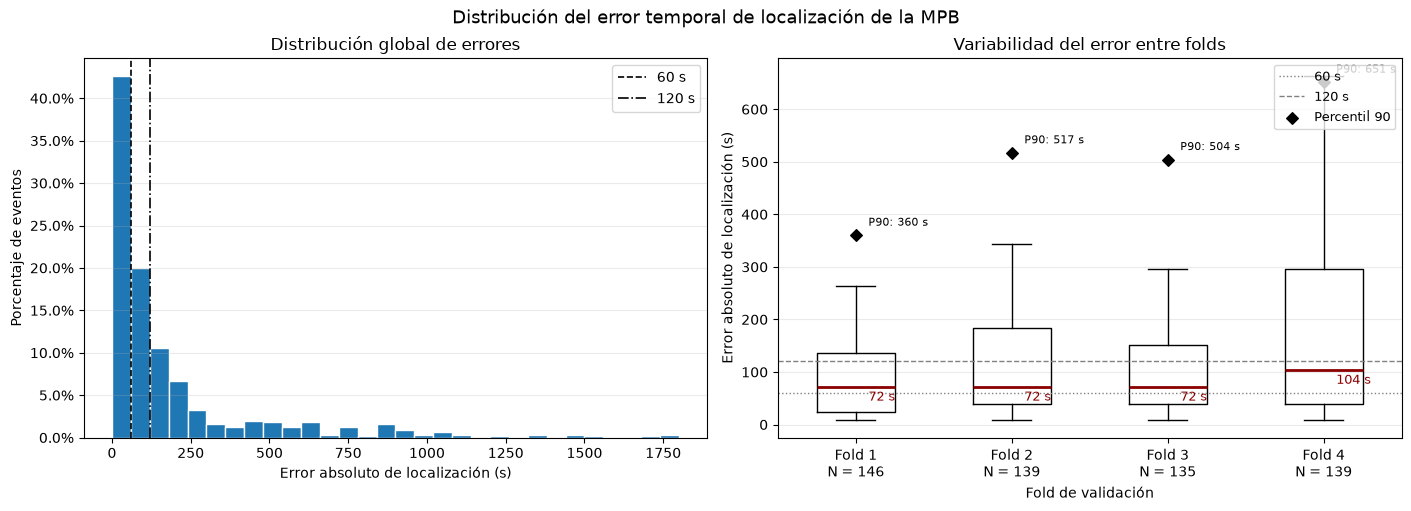

,fold,N,N_evaluable,mediana_s,p90_s,dentro_60,dentro_120
0,1,146,146,72.0,360.0,48.6%,71.2%
1,2,139,139,72.0,516.8,43.9%,68.3%
2,3,135,135,72.0,504.0,43.7%,65.9%
3,4,139,139,104.0,651.2,33.8%,56.8%


In [11]:

# 6.3 Distribución porcentual de errores y métricas entre folds.

from matplotlib.ticker import PercentFormatter

if run_dir is not None:

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5),
        layout='constrained'
    )

    # --------------------------------------------------
    # FIGURA 1: distribución global porcentual de errores
    # --------------------------------------------------

    error_values = (
        all_events['absolute_error_s']
        .dropna()
        .to_numpy()
    )

    if len(error_values) > 0:

        # Cada evento aporta 100/N puntos porcentuales.
        weights = np.full(
            len(error_values),
            100.0 / len(error_values)
        )

        axes[0].hist(
            error_values,
            bins=np.arange(0, 1840, 60),
            weights=weights,
            edgecolor='white'
        )

        # Referencias temporales
        for mark, style, label in [
            (60, '--', '60 s'),
            (120, '-.', '120 s')
        ]:
            axes[0].axvline(
                mark,
                ls=style,
                color='black',
                linewidth=1.2,
                label=label
            )

        axes[0].yaxis.set_major_formatter(
            PercentFormatter(xmax=100)
        )

        axes[0].set(
            xlabel='Error absoluto de localización (s)',
            ylabel='Porcentaje de eventos',
            title='Distribución global de errores'
        )

        axes[0].legend()

        axes[0].grid(
            axis='y',
            alpha=0.25
        )

    # --------------------------------------------------
    # FIGURA 2: comparación entre folds
    # --------------------------------------------------

    group = [
        all_events.loc[
            all_events.fold == k,
            'absolute_error_s'
        ].dropna().to_numpy()
        for k in range(1, 5)
    ]

    axes[1].boxplot(
        group,
        showfliers=False,
        widths=0.5,
        medianprops={
            'color': 'darkred',
            'linewidth': 2
        }
    )

    # Etiquetas con cantidad de eventos
    axes[1].set_xticks(
        range(1, 5),
        [
            f'Fold {k}\nN = {len(group[k-1])}'
            for k in range(1, 5)
        ]
    )

    # Líneas de referencia
    axes[1].axhline(
        60,
        ls=':',
        color='gray',
        lw=1,
        label='60 s'
    )

    axes[1].axhline(
        120,
        ls='--',
        color='gray',
        lw=1,
        label='120 s'
    )

    # Mediana y percentil 90 por fold
    for k, values in enumerate(group, 1):

        if len(values) == 0:
            continue

        median = np.median(values)
        p90 = np.percentile(values, 90)

        # Etiqueta de la mediana
        axes[1].annotate(
            f'{median:.0f} s',
            xy=(k, median),
            xytext=(9, -10),
            textcoords='offset points',
            fontsize=9,
            color='darkred',
            ha='left'
        )

        # Marcador del percentil 90
        axes[1].scatter(
            k,
            p90,
            marker='D',
            s=35,
            color='black',
            zorder=5,
            label='Percentil 90' if k == 1 else None
        )

        axes[1].annotate(
            f'P90: {p90:.0f} s',
            xy=(k, p90),
            xytext=(9, 5),
            textcoords='offset points',
            fontsize=8,
            ha='left',
            va='bottom'
        )

    axes[1].set(
        xlabel='Fold de validación',
        ylabel='Error absoluto de localización (s)',
        title='Variabilidad del error entre folds'
    )

    axes[1].grid(
        axis='y',
        alpha=0.25
    )

    axes[1].legend(
        fontsize=9,
        loc='upper right'
    )

    fig.suptitle(
        'Distribución del error temporal de localización de la MPB',
        fontsize=13
    )

    fig.savefig(
        FIG_DIR / '07_errores_localizacion.png',
        dpi=170
    )

    plt.show()

    # --------------------------------------------------
    # TABLA DE MÉTRICAS POR FOLD
    # --------------------------------------------------

    fold_table = pd.DataFrame([
        {
            'fold': k,
            'N': m['val_total_events'],
            'N_evaluable': m['val_evaluable_events'],
            'mediana_s': m['median_abs_peak_error_s'],
            'p90_s': m['p90_abs_peak_error_s'],
            'dentro_60': m['fraction_within_60s'],
            'dentro_120': m['fraction_within_120s']
        }
        for k, m in sorted(fold_metrics.items())
    ])

    display(
        fold_table.style.format({
            'mediana_s': '{:.1f}',
            'p90_s': '{:.1f}',
            'dentro_60': '{:.1%}',
            'dentro_120': '{:.1%}'
        })
    )

else:
    print(
        'Distribución de errores no disponible '
        'sin resultados compatibles.'
    )


### Análisis de los errores de localización temporal

En la figura anterior presento la distribución de los errores absolutos de localización de la MPB obtenidos durante la validación cruzada, considerando los eventos evaluables de los cuatro folds.

**Distribución global de errores**

En el primer gráfico represento el porcentaje de eventos en función del error absoluto de localización, utilizando intervalos de 60 segundos. Esta representación permite identificar qué proporción de los cruces presenta errores pequeños y cómo se distribuyen aquellos eventos para los cuales la estimación temporal resulta menos precisa.

Incorporé líneas verticales de referencia en 60 y 120 segundos para facilitar la interpretación de los resultados. Estas referencias permiten relacionar visualmente la distribución con las métricas de localización dentro de uno y dos minutos.

El análisis de esta distribución es importante porque la mediana, por sí sola, no describe completamente el comportamiento del modelo. Dos modelos pueden presentar errores medianos similares y, sin embargo, diferir considerablemente en la proporción de eventos con errores elevados.

**Comparación entre folds**

En el segundo gráfico comparo las distribuciones de los errores absolutos correspondientes a cada fold de validación.

Esta comparación permite estudiar la estabilidad del modelo frente a diferentes conjuntos de eventos y determinar si su capacidad de localización temporal depende significativamente de los datos utilizados durante el entrenamiento.

Para complementar la comparación, incluyo las medianas, los percentiles 90 y la cantidad de eventos evaluables de cada fold. De esta manera, puedo analizar tanto el error típico como el comportamiento de los eventos con mayores errores.

Las diferencias entre folds deben interpretarse considerando que cada partición contiene eventos correspondientes a distintos períodos de observación, que pueden presentar condiciones físicas y características de las transiciones diferentes.

**Interpretación de los resultados**

A diferencia de las funciones de pérdida presentadas anteriormente, que permiten estudiar la evolución del entrenamiento y la selección de los checkpoints, estas figuras evalúan directamente la capacidad del modelo para localizar temporalmente los cruces catalogados de la MPB.

Por lo tanto, constituyen una evaluación más directamente relacionada con el objetivo científico del trabajo.

Sin embargo, los errores corresponden a una búsqueda realizada alrededor de cruces previamente conocidos. En consecuencia, estos resultados caracterizan la precisión temporal de localización del modelo, pero no permiten establecer todavía su capacidad de detectar MPB desconocidas en series temporales continuas.

## 7. Ejemplo de localización: curva de puntuación temporal

Para un evento del **fold externo**, evaluamos cada centro de ventana conjunto MAG+SWEA dentro de ±30 min de la MPB catalogada. El tiempo del máximo de la función sigmoide del logit de transición es el tiempo predicho. **La anotación solo define el intervalo de evaluación y permite medir el error; no entra en la red como predictor.**

El modelo y los normalizadores se leen del checkpoint real elegido por el monitor interno. Se utiliza únicamente la caché físicamente medida.


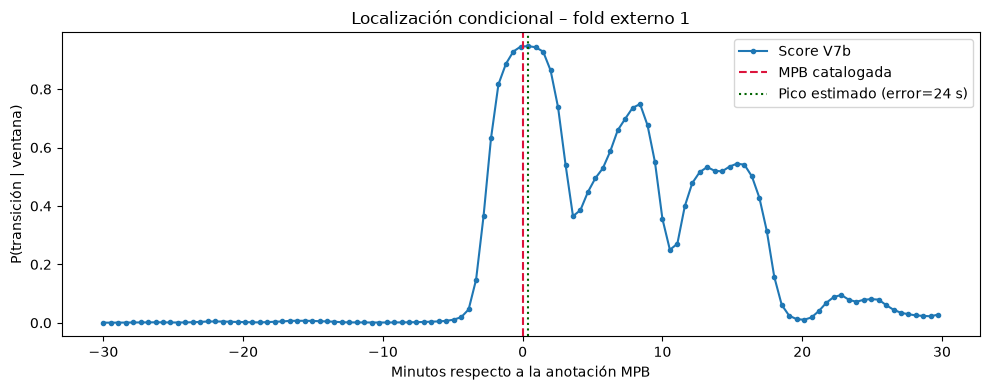

In [13]:
# 7.1 Helpers para checkpoint y scoring del evento de validación.
from src.model.v7b import MagSweaRegionAutoencoder
@torch.no_grad()
def load_fold_model(fold):
    if run_dir is None:
        return None,None
    info=fold_metrics[fold]
    checkpoint=torch.load(run_dir/f'fold_{fold:02d}_final.pt',map_location='cpu',weights_only=False)
    assert checkpoint['signature']==info['signature'], 'Checkpoint y métricas incompatibles.'
    model=MagSweaRegionAutoencoder().eval()
    model.load_state_dict(checkpoint['model'])
    norm={k:{'mean':np.asarray(v['mean']),'scale':np.asarray(v['scale'])}
          for k,v in checkpoint['normalizers'].items()}
    return model,norm

all_mpb_s=np.array([r['time'].timestamp() for r in rows])
all_bs_s=np.array([r['bs_time'].timestamp() for r in rows])

@torch.no_grad()
def score_event(row,pair,model,norm):
    proposals,_=trainer.gather_candidates([row],{row['time']:pair},
                        all_mpb_s,all_bs_s,evaluate=True,stride_s=CFG.evaluation_stride_s)
    prepared=proposals.get(row['time'],[])
    offsets,scores=[],[]
    for begin in range(0,len(prepared),CFG.batch_size):
        group=prepared[begin:begin+CFG.batch_size]
        batch=collate_dual([(clip, c.transition if c.transition is not None else 0,
                             (c.left_region,c.right_region) if c.left_region is not None else (0,0))
                            for c,clip in group],norm,device='cpu')
        out=model(batch['mag'],batch['mag_mask'],batch['mag_time'],
                  batch['swea'],batch['swea_mask'],batch['swea_time'])
        prob=torch.sigmoid(out['transition_logit']).numpy()
        offsets.extend([(c.center_s-row['time'].timestamp()) for c,clip in group])
        scores.extend(prob.tolist())
    return np.array(offsets),np.array(scores)

if run_dir is not None:
    demo_model,demo_norm=load_fold_model(FOLD_TO_VISUALIZE)
    if sample_pair is None or sample_row['fold']!=FOLD_TO_VISUALIZE:
        sample_row,sample_pair=find_cached_event(FOLD_TO_VISUALIZE)
    if sample_pair is not None:
        dx,dy=score_event(sample_row,sample_pair,demo_model,demo_norm)
        if len(dx):
            j=np.argmax(dy)
            fig,ax=plt.subplots(figsize=(10,4))
            ax.plot(dx/60,dy,'o-',ms=3,label='Score V7b')
            ax.axvline(0,c='crimson',ls='--',label='MPB catalogada')
            ax.axvline(dx[j]/60,c='darkgreen',ls=':',label=f'Pico estimado (error={abs(dx[j]):.0f} s)')
            ax.set(xlabel='Minutos respecto a la anotación MPB',ylabel='P(transición | ventana)',
                   title=f'Localización condicional – fold externo {FOLD_TO_VISUALIZE}')
            ax.legend();fig.tight_layout();fig.savefig(FIG_DIR/'08_score_temporal.png',dpi=180);plt.show()
        else: print('La ventana de ejemplo no tiene candidatos evaluables.')
    else: print('No hay evento con mediciones cacheadas para el ejemplo.')
else: print('No hay checkpoint compatible para el ejemplo de score.')


## 8. Análisis del espacio latente

Hasta este punto evalué el comportamiento de la red neuronal a partir de sus funciones de pérdida y de los errores temporales de localización de la MPB. Sin embargo, también me interesa investigar qué características de las mediciones de MAG y SWEA aprendió el modelo durante el entrenamiento.

Para ello, analizo las representaciones latentes generadas por los codificadores convolucionales de ambos instrumentos.

Como describí en la sección 4, cada codificador transforma las señales originales en **16 canales latentes temporales**. Estos canales no representan directamente magnitudes físicas conocidas, sino características que la red aprendió a extraer para cumplir sus objetivos de clasificación, ranking y reconstrucción.

El objetivo de este análisis es explorar si las representaciones aprendidas presentan diferencias entre las ventanas próximas a cruces catalogados de la MPB y los controles negativos seleccionados mediante los criterios físicos establecidos anteriormente.

### 8.1. Extracción de las representaciones latentes

Para estudiar el espacio latente utilizo los modelos ya entrenados, sin modificar sus parámetros.

Selecciono uno de los folds externos y recupero el checkpoint correspondiente. De esta manera, las representaciones que analizo se obtienen a partir de eventos que no participaron del entrenamiento ni de la selección de ese modelo.

Para cada ventana candidata introduzco las mediciones normalizadas de MAG y SWEA en sus respectivos codificadores y recupero directamente las salidas latentes, antes de que ingresen a los decodificadores o a las redes de clasificación.

Para MAG obtengo:

[
Z\_{\mathrm{MAG}}\in\mathbb R^{16\times T\_{\mathrm{MAG}}}
]

y para SWEA:

[
Z\_{\mathrm{SWEA}}\in\mathbb R^{16\times T\_{\mathrm{SWEA}}}
]

donde (T\_{\mathrm{MAG}}) y (T\_{\mathrm{SWEA}}) representan las cantidades de muestras temporales disponibles para cada instrumento.

Cada una de las 16 filas de estas matrices corresponde a una característica aprendida por la red y contiene su evolución temporal dentro de la ventana de 10 minutos.

**Construcción de los vectores de características**

Para poder comparar distintas ventanas necesito transformar estas matrices en vectores de dimensión fija.

Utilizo el mismo procedimiento de promedio temporal que implementé en la arquitectura del modelo.

Primero calculo el promedio de cada canal latente en el intervalo anterior al centro de la ventana, considerando las muestras con tiempos relativos menores que −60 segundos.

Después repito el procedimiento utilizando las muestras posteriores a +60 segundos.

Para cada instrumento obtengo así dos vectores de 16 componentes:

[
\mathbf z\_{\mathrm{izq}}\in\mathbb R^{16}
\qquad
\mathbf z\_{\mathrm{der}}\in\mathbb R^{16}
]

Concatenando ambos vectores construyo una representación de 32 componentes:

[
\mathbf v=
[\mathbf z\_{\mathrm{izq}},\mathbf z\_{\mathrm{der}}]
]

Realizo este procedimiento por separado para MAG y SWEA. Por lo tanto, cada ventana queda asociada a un vector de 32 características magnéticas y otro de 32 características electrónicas.

Esta representación contiene información aprendida sobre las condiciones anteriores y posteriores al centro candidato, aunque no permite identificar directamente el significado físico de cada componente.

**Selección de ventanas para el análisis**

Para realizar una primera exploración selecciono eventos del fold externo que cuentan con mediciones MAG y SWEA disponibles en caché.

De cada evento considero una ventana positiva próxima al instante catalogado de la MPB y hasta dos controles negativos conservadores.

Las ventanas positivas y negativas se identifican mediante las etiquetas débiles utilizadas anteriormente, pero estas etiquetas no se introducen como entradas a los codificadores.

En la configuración actual limito el análisis a un máximo de 24 eventos del fold seleccionado, para obtener una primera visualización del espacio latente sin procesar nuevamente todo el catálogo.

### 8.2. Reducción de dimensionalidad mediante PCA

Una vez obtenidos los vectores latentes, utilizo el método de análisis de componentes principales (*Principal Component Analysis*, PCA) para visualizar sus características.

PCA es un procedimiento de reducción de dimensionalidad que construye nuevas variables a partir de combinaciones lineales de las características originales.

En mi caso, cada ventana está representada por un vector de 32 componentes. Mediante PCA reduzco esa representación a dos coordenadas:

[
\mathbf v\in\mathbb R^{32}
\quad\xrightarrow{\mathrm{PCA}}\quad
(PC1,PC2)
]

Realizo el análisis por separado para MAG y SWEA, ya que sus codificadores aprenden representaciones diferentes.

De esta manera, puedo visualizar cada ventana como un punto en un plano y distinguir mediante colores las ventanas positivas próximas a la MPB y los controles negativos.



In [25]:

# 8.1 Extracción de embeddings latentes de los cuatro folds externos.
# Se utilizan los checkpoints entrenados y las mediciones en caché.

import numpy as np
import pandas as pd
import torch

from src.model.v7b import masked_region_pool
from src.preprocessing.native_windows import collate_dual

MAX_LATENT_EVENTS_PER_FOLD = 24

latent_records = []
latent_example = None


@torch.no_grad()
def latent_vector(model, norm, clip, side_offset=60.0):

    batch = collate_dual(
        [(clip, 0, (0, 0))],
        norm,
        device='cpu'
    )

    model.eval()

    # Representaciones latentes de los dos encoders.
    # Cada encoder devuelve (latente, reconstruccion).
    zm, _ = model.mag(
        batch['mag'],
        batch['mag_mask']
    )

    ze, _ = model.swea(
        batch['swea'],
        batch['swea_mask']
    )

    vectors = {}

    for name, z in [('MAG', zm), ('SWEA', ze)]:

        mask = batch[name.lower() + '_mask']
        rel = batch[name.lower() + '_time']

        # Promedio de los canales latentes antes del centro.
        left = masked_region_pool(
            z, mask, rel,
            side='left',
            gap_s=side_offset
        )

        # Promedio de los canales latentes despues del centro.
        right = masked_region_pool(
            z, mask, rel,
            side='right',
            gap_s=side_offset
        )

        # Vector de 32 componentes:
        # 16 anteriores + 16 posteriores.
        vectors[name] = torch.cat(
            [left, right], dim=1
        ).squeeze(0).cpu().numpy()

    # Mapas temporales completos para la celda 8.3.
    maps = {
        'MAG': (
            zm.squeeze(0).cpu().numpy(),
            batch['mag_time'].squeeze(0).cpu().numpy()
        ),
        'SWEA': (
            ze.squeeze(0).cpu().numpy(),
            batch['swea_time'].squeeze(0).cpu().numpy()
        )
    }

    return vectors, maps


# Instantes catalogados de MPB y Bow Shock.
all_mpb_s = np.array([
    r['time'].timestamp() for r in rows
])

all_bs_s = np.array([
    r['bs_time'].timestamp() for r in rows
])


# --------------------------------------------------
# Extraccion de embeddings para los cuatro folds
# --------------------------------------------------

if run_dir is not None:

    for fold in range(1, 5):

        latent_model, latent_norm = load_fold_model(fold)

        if latent_model is None:
            print(f'Fold {fold}: sin checkpoint compatible.')
            continue

        accepted = 0

        candidates = [
            r for r in rows
            if r['fold'] == fold
            and r['mag_available'] == '1'
            and r['swea_available'] == '1'
        ]

        for row in candidates:

            pair = load_cached_pair(row)

            if pair is None:
                continue

            prepared, _ = trainer.gather_candidates(
                [row],
                {row['time']: pair},
                all_mpb_s,
                all_bs_s,
                ranking=True,
                rank_control_step_s=CFG.rank_control_step_s
            )

            items = prepared.get(row['time'], [])

            # Separar ventanas positivas y negativas.
            positives = [
                (c, clip)
                for c, clip in items
                if c.transition == 1
            ]

            negatives = [
                (c, clip)
                for c, clip in items
                if c.transition == 0
            ]

            if not positives or not negatives:
                continue

            # Seleccionar el positivo mas cercano a la MPB.
            positives = sorted(
                positives,
                key=lambda item: abs(
                    item[0].center_s -
                    row['time'].timestamp()
                )
            )

            # Una ventana positiva y hasta dos negativas.
            selected = positives[:1] + negatives[:2]

            for c, clip in selected:

                vectors, maps = latent_vector(
                    latent_model,
                    latent_norm,
                    clip
                )

                latent_records.append({
                    'event': row['time'].isoformat(),
                    'fold': fold,
                    'group': row['source_group'],
                    'weak_label': int(c.transition),
                    'label_name': (
                        'Ventana positiva'
                        if c.transition == 1
                        else 'Ventana negativa de control'
                    ),
                    'MAG': vectors['MAG'],
                    'SWEA': vectors['SWEA']
                })

                # Conservar un ejemplo para los mapas temporales.
                if c.transition == 1:
                    example = {
                        'row': row,
                        'maps': maps,
                        'clip': clip,
                        'fold': fold
                    }

                    if (
                        latent_example is None
                        or (
                            fold == FOLD_TO_VISUALIZE
                            and latent_example['fold'] != FOLD_TO_VISUALIZE
                        )
                    ):
                        latent_example = example

            accepted += 1

            if accepted >= MAX_LATENT_EVENTS_PER_FOLD:
                break

        print(
            f'Fold {fold}: {accepted} eventos procesados.'
        )

else:
    print('No hay checkpoints compatibles.')


# --------------------------------------------------
# Resumen de las ventanas extraidas
# --------------------------------------------------

print('\nResumen de representaciones latentes:')

if latent_records:

    latent_summary = pd.DataFrame([
        {
            'Fold': r['fold'],
            'Etiqueta': r['weak_label']
        }
        for r in latent_records
    ])

    counts = pd.crosstab(
        latent_summary['Fold'],
        latent_summary['Etiqueta']
    ).reindex(
        index=range(1, 5),
        columns=[0, 1],
        fill_value=0
    )

    counts.columns = [
        'Ventanas negativas',
        'Ventanas positivas'
    ]

    counts['Total'] = counts.sum(axis=1)

    display(counts)

print(f'Total de ventanas: {len(latent_records)}')


Fold 1: 24 eventos procesados.
Fold 2: 24 eventos procesados.
Fold 3: 24 eventos procesados.
Fold 4: 24 eventos procesados.

Resumen de representaciones latentes:


,Ventanas negativas,Ventanas positivas,Total
Fold,,,
1,48,24,72
2,48,24,72
3,48,24,72
4,48,24,72


Total de ventanas: 288


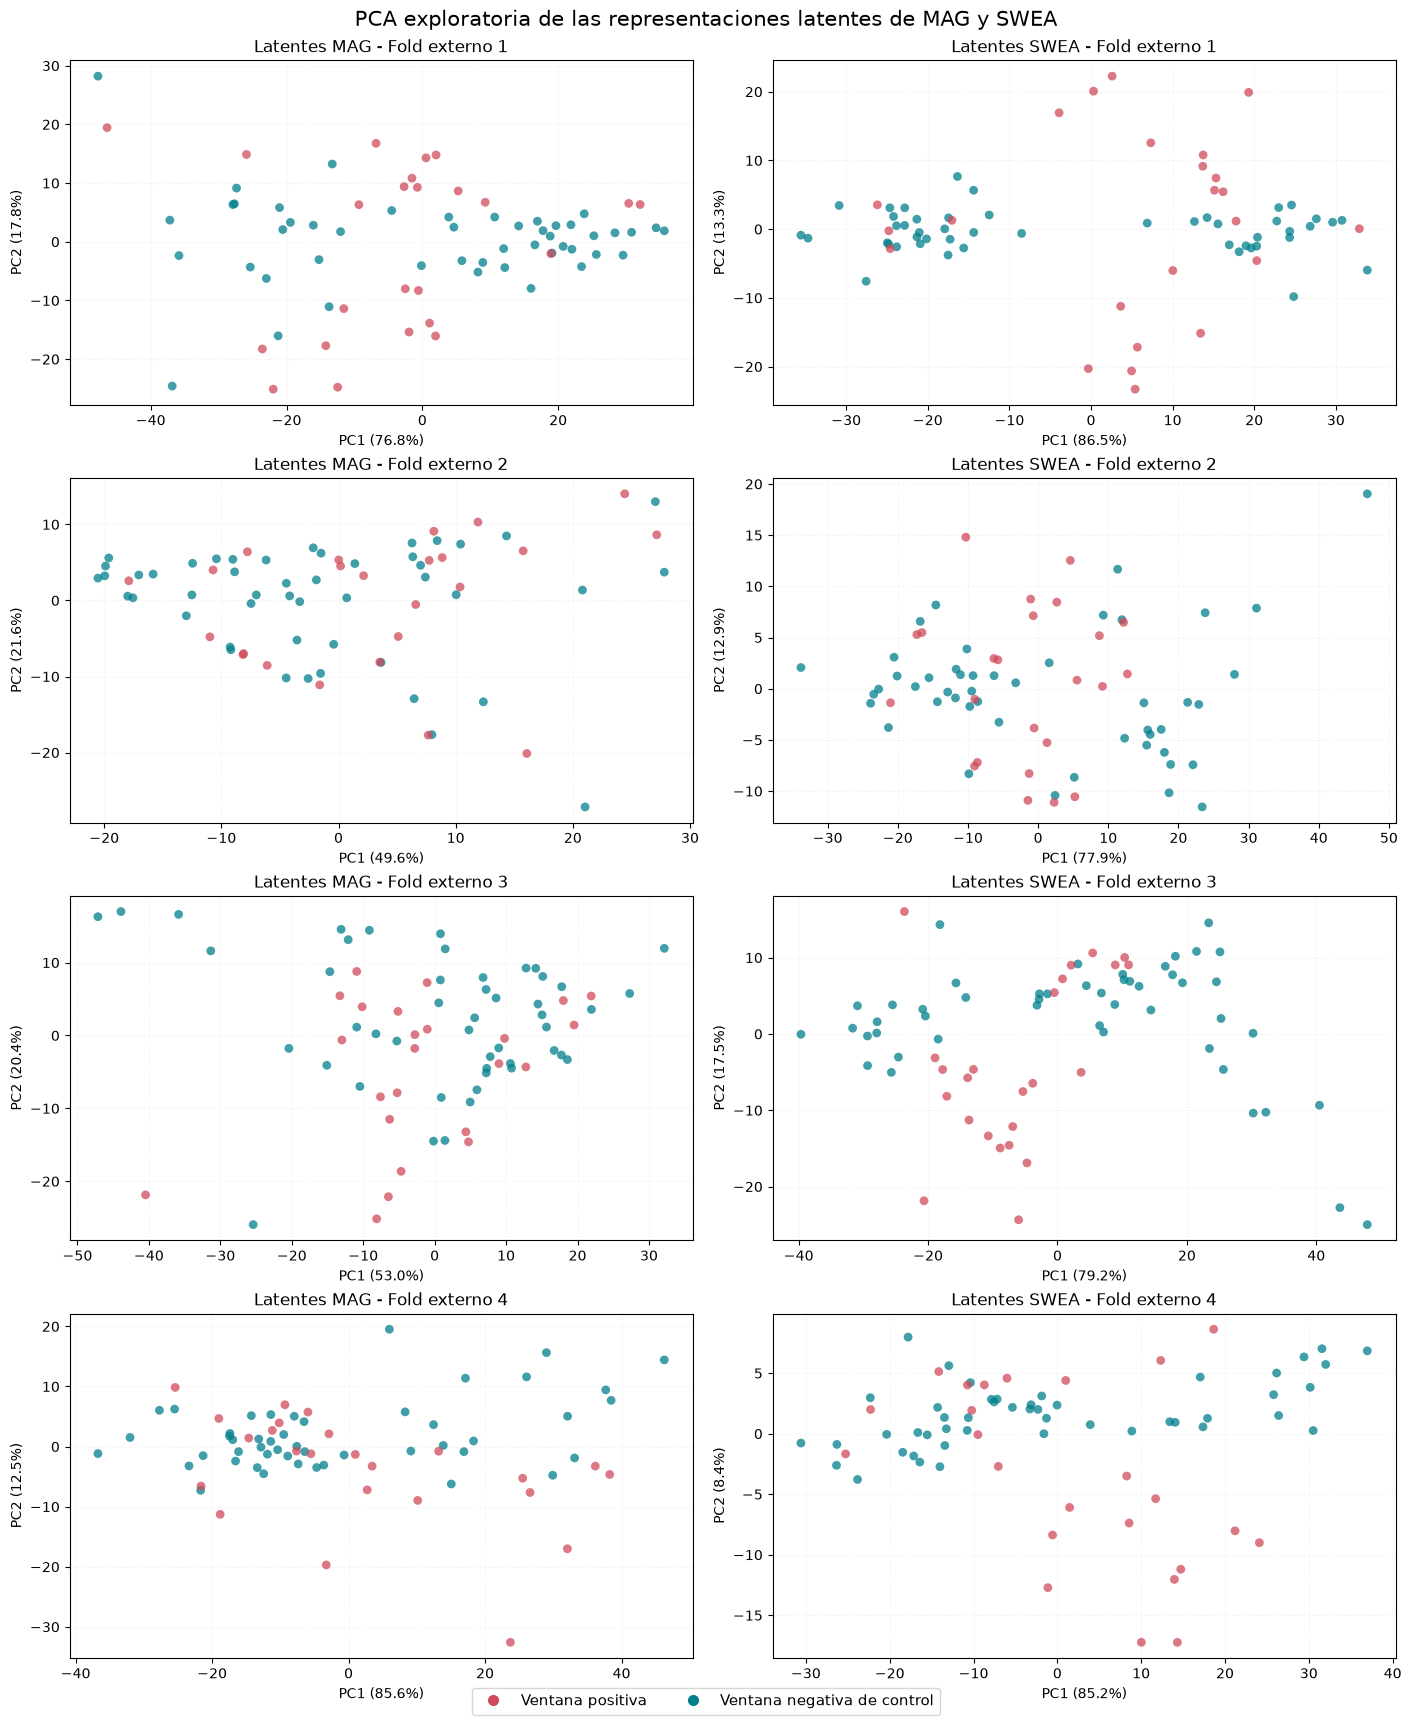

,Fold,Instrumento,N ventanas,N positivas,N negativas,PC1,PC2,Varianza total
0,1,MAG,72,24,48,76.8%,17.8%,94.6%
1,1,SWEA,72,24,48,86.5%,13.3%,99.8%
2,2,MAG,72,24,48,49.6%,21.6%,71.2%
3,2,SWEA,72,24,48,77.9%,12.9%,90.7%
4,3,MAG,72,24,48,53.0%,20.4%,73.5%
5,3,SWEA,72,24,48,79.2%,17.5%,96.6%
6,4,MAG,72,24,48,85.6%,12.5%,98.1%
7,4,SWEA,72,24,48,85.2%,8.4%,93.6%


In [26]:

# 8.2 PCA exploratoria por instrumento y por fold externo.
# Cada modelo tiene su propio espacio latente.
# Por eso se ajusta una PCA independiente para cada fold.

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from matplotlib.lines import Line2D


# Colores de las etiquetas debiles.
colors = {
    1: '#d1495b',  # Ventanas positivas
    0: '#007f8c'   # Ventanas negativas
}

names = {
    1: 'Ventana positiva',
    0: 'Ventana negativa de control'
}


if len(latent_records) == 0:

    print('No hay representaciones latentes disponibles.')

else:

    fig, axes = plt.subplots(
        4, 2,
        figsize=(14, 17),
        layout='constrained'
    )

    pca_summary = []

    for fold in range(1, 5):

        # Seleccionar solamente ventanas del fold actual.
        fold_records = [
            r for r in latent_records
            if r['fold'] == fold
        ]

        labels = np.array([
            r['weak_label']
            for r in fold_records
        ])

        for col, sensor in enumerate(['MAG', 'SWEA']):

            ax = axes[fold - 1, col]

            # Verificar que haya suficientes ventanas
            # y que esten presentes ambas clases.
            if (
                len(fold_records) < 3
                or len(np.unique(labels)) < 2
            ):

                ax.text(
                    0.5, 0.5,
                    'Datos insuficientes',
                    transform=ax.transAxes,
                    ha='center',
                    va='center'
                )

                ax.set_title(
                    f'{sensor} - Fold {fold}'
                )

                continue

            # Cada vector tiene 32 componentes.
            X = np.stack([
                r[sensor]
                for r in fold_records
            ])

            # Ajustar PCA exclusivamente con este fold.
            pca = PCA(
                n_components=2,
                svd_solver='full'
            )

            xy = pca.fit_transform(X)

            explained = pca.explained_variance_ratio_

            # Graficar las dos clases.
            for value in [0, 1]:

                subset = labels == value

                ax.scatter(
                    xy[subset, 0],
                    xy[subset, 1],
                    s=40,
                    alpha=0.75,
                    color=colors[value],
                    label=names[value],
                    edgecolors='none'
                )

            # Etiquetas de los ejes.
            ax.set_xlabel(
                f'PC1 ({explained[0]:.1%})'
            )

            ax.set_ylabel(
                f'PC2 ({explained[1]:.1%})'
            )

            ax.set_title(
                f'Latentes {sensor} - Fold externo {fold}'
            )

            ax.grid(
                alpha=0.2,
                linestyle=':'
            )

            ax.set_axisbelow(True)

            # Registrar estadisticas de la PCA.
            pca_summary.append({
                'Fold': fold,
                'Instrumento': sensor,
                'N ventanas': len(fold_records),
                'N positivas': int(np.sum(labels == 1)),
                'N negativas': int(np.sum(labels == 0)),
                'PC1': explained[0],
                'PC2': explained[1],
                'Varianza total': explained.sum()
            })

    # --------------------------------------------------
    # Leyenda general
    # --------------------------------------------------

    legend_handles = [
        Line2D(
            [0], [0],
            marker='o',
            linestyle='None',
            markerfacecolor=colors[1],
            markeredgecolor='none',
            markersize=8,
            label=names[1]
        ),
        Line2D(
            [0], [0],
            marker='o',
            linestyle='None',
            markerfacecolor=colors[0],
            markeredgecolor='none',
            markersize=8,
            label=names[0]
        )
    ]

    fig.legend(
        handles=legend_handles,
        loc='lower center',
        ncol=2,
        fontsize=11,
        bbox_to_anchor=(0.5, -0.01)
    )

    fig.suptitle(
        'PCA exploratoria de las representaciones latentes '
        'de MAG y SWEA',
        fontsize=15
    )

    fig.savefig(
        FIG_DIR / '09_PCA_latente_MAG_SWEA.png',
        dpi=180,
        bbox_inches='tight'
    )

    plt.show()

    # --------------------------------------------------
    # Tabla con varianza explicada
    # --------------------------------------------------

    if pca_summary:

        pca_table = pd.DataFrame(pca_summary)

        display(
            pca_table.style.format({
                'PC1': '{:.1%}',
                'PC2': '{:.1%}',
                'Varianza total': '{:.1%}'
            }).set_caption(
                'Varianza explicada por las componentes '
                'principales de cada fold'
            )
        )


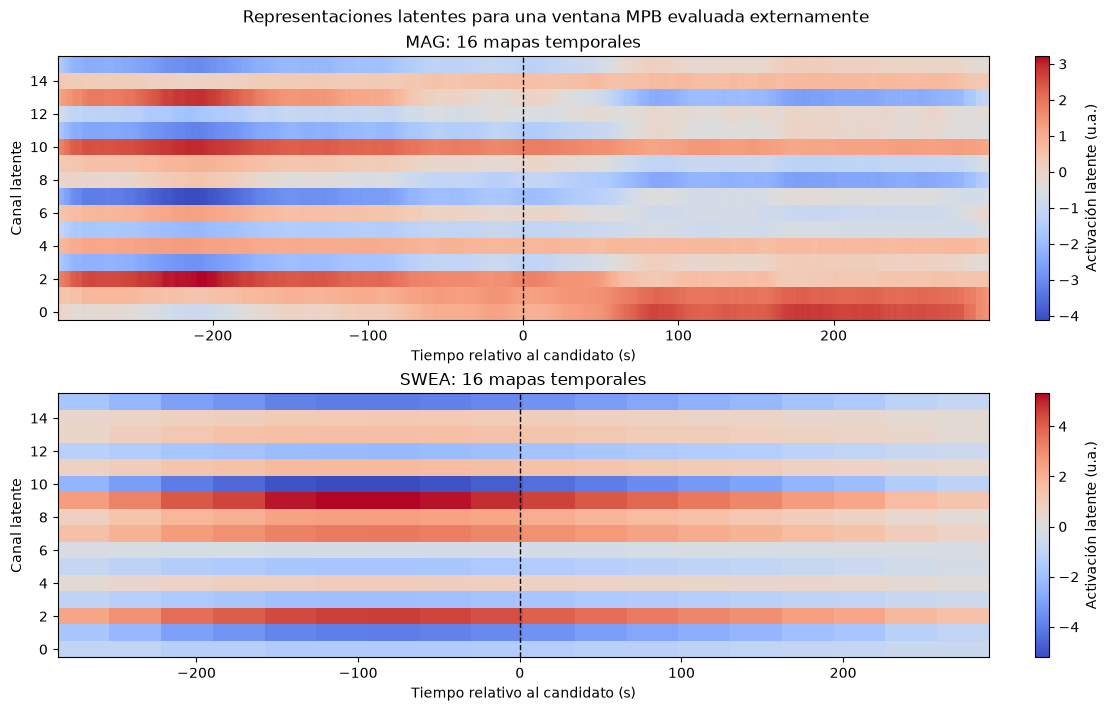

In [27]:
# 8.3 Mapas latentes z(canal, tiempo): respetan los instantes nativos de cada instrumento.
if latent_example is not None:
    fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained')
    for ax,sensor in zip(axes,['MAG','SWEA']):
        zz,t=latent_example['maps'][sensor]
        # pcolormesh ubica cada columna en SU tiempo nativo, sin remuestrear.
        pc=ax.pcolormesh(t,np.arange(zz.shape[0]),zz,shading='nearest',cmap='coolwarm')
        ax.axvline(0,c='black',ls='--',lw=1)
        ax.set(xlabel='Tiempo relativo al candidato (s)',ylabel='Canal latente',
               title=f'{sensor}: {zz.shape[0]} mapas temporales')
        fig.colorbar(pc,ax=ax,label='Activación latente (u.a.)')
    fig.suptitle('Representaciones latentes para una ventana MPB evaluada externamente')
    fig.savefig(FIG_DIR/'10_mapas_latentes_temporales.png',dpi=180);plt.show()
else:
    print('Mapas no disponibles hasta disponer de mediciones y checkpoint del fold.')


## 9. Discusión y conclusiones

En este trabajo desarrollé una red neuronal convolucional que combina las mediciones de MAG y SWEA de MAVEN para estudiar la localización temporal de la Magnetic Pileup Boundary (MPB) de Marte. El modelo utiliza supervisión débil a partir de cruces catalogados y combina objetivos de clasificación, ranking de candidatos y reconstrucción de las señales.

Mediante una validación cruzada de cuatro folds evalué la capacidad de la red para localizar los cruces dentro de intervalos de ±30 minutos alrededor de las MPB catalogadas. Los resultados muestran que el modelo logra aprender durante el entrenamiento, aunque la precisión temporal de las predicciones varía entre eventos y folds.

También exploré las representaciones latentes aprendidas por los codificadores de MAG y SWEA mediante PCA. En general, observé un solapamiento considerable entre las ventanas positivas y los controles negativos, sin una separación clara entre ambos grupos. Sin embargo, esto no implica necesariamente que la red no haya aprendido características útiles, ya que la clasificación de transición utiliza combinaciones no lineales de las representaciones latentes.

La principal limitación del modelo es que **la evaluación se realiza alrededor de cruces previamente conocidos**. Por lo tanto, los resultados permiten caracterizar su capacidad de localización temporal, pero todavía no demuestran que pueda detectar MPB de manera autónoma en series continuas.

**Posibles mejoras y trabajos futuros**

Para intentar reducir el error temporal de localización durante la validación, considero interesante explorar distintas modificaciones de la arquitectura y del procedimiento de entrenamiento:

- **Incorporar información de la región central de las ventanas:** actualmente la clasificación utiliza principalmente las representaciones anteriores y posteriores al centro candidato. Incluir explícitamente las características latentes de la zona central podría ayudar a reconocer estructuras más localizadas de la MPB.
- **Modificar la función de pérdida:** estudiar alternativas que penalicen de manera más directa la distancia temporal entre el instante estimado y el cruce catalogado, además de las pérdidas de clasificación y ranking utilizadas actualmente.
- **Optimizar los hiperparámetros:** analizar diferentes pesos de las funciones de pérdida, tamaños de ventana, arquitecturas convolucionales y criterios de detención temprana, utilizando exclusivamente los datos de entrenamiento y monitoreo para seleccionar las configuraciones.
- **Mejorar la selección de candidatos:** investigar estrategias de muestreo que incorporen ejemplos más difíciles y permitan distinguir mejor las ventanas próximas a la MPB de aquellas alejadas de la transición.
- **Aumentar la resolución temporal de evaluación:** reducir el espaciamiento de 32 segundos entre los centros candidatos para obtener una estimación temporal más fina, aunque esto no garantiza por sí solo una disminución del error.

También considero importante estudiar las diferencias entre las representaciones latentes anteriores y posteriores a cada candidato y comparar el desempeño de MAG y SWEA por separado, para determinar cuánto aporta cada instrumento a la localización.

Finalmente, sería necesario evaluar el modelo sobre intervalos que no contengan necesariamente cruces catalogados y utilizar datos independientes para comprobar si las mejoras se generalizan. Esto permitiría avanzar hacia un sistema de detección y localización automática de la MPB a partir de las observaciones de MAVEN.